# 信用創造はどこで止まるのか
## ――「信用創造ダイナミクス v5」を読み解き、利子が経済に戻るモデルへ組み直す

文責: JRF ( http://jrf.cocolog-nifty.com/statuses/ )<br>
モデル化・執筆の補助: Claude Opus 5.5 (Anthropic)<br>
2026年10月

---

### この文書について

「預金はすぐに貸し出され、貸し出されたお金は誰かの所得になり、その一部がまた預金になる。そうだとすると、経済は無限に膨らめるのではないか。それを止めているのは何なのか。」

この文書は、この素朴な問いから出発する。JRF は以前、AI(Claude)と一緒に、この問いを差分方程式のシミュレーション「信用創造ダイナミクス」(v1〜v5)にまとめた([GitHub misc_html](https://github.com/JRF-2018/misc_html) に公開)。この文書では、その最終版 v5 を

1. 式として正確に読み、何を言っているモデルなのかを確かめる。
2. 長く走らせたり、定常状態を解いたりして、隠れた性質(と弱点)を見つける。
3. とくに議論になった「分配集中度 Φ」と「実効準備率 ρ_eff」の式
   $$\Phi = \frac{rC}{\max(Y,\varepsilon)},\qquad \rho_{\rm eff} = \rho + \mu\cdot\max(0,\Phi-\theta)$$
   が妥当かを、別の角度から導き直して検討する。
4. その上で、利子が誰かの所得として経済に戻る「ストック・フロー一貫」の二階級モデルを組み、国家と労働も入れてシミュレーションで論じる。

という順で、初学者にも追えるように一から組み立て直す。

**読み方**: コードセルは上から順に実行すれば全部動く(numpy, scipy, matplotlib のみ使用。Google Colab でもそのまま動く)。図の軸ラベルは、環境に日本語フォントがなくても文字化けしないよう英語にしてある。図の説明は本文で日本語で行う。

### 目次

0. 準備(作図の設定)
1. 素朴な信用創造: 無限の連鎖と「漏れ」
2. 銀行の二つの制度: 量の制度と金利の制度
3. v5 を式で読む
4. v5 を長く走らせる: 崩壊は必ず来る
5. v5 の定常状態が安定である条件
6. Φ と ρ_eff は正しいか: 導き直しと批判
7. 改良モデル: 利子が戻る二階級の信用循環モデル
8. 実験 1: 金利と準備率の非対称
9. 実験 2: タンス預金はいつ効くのか
10. 実験 3: 金利生活者の貯蓄と長期停滞
11. 実験 4: 株式的富のブームと崩壊、在庫維持能力
12. 金利の三つの経路
13. 国家を入れる
14. 労働を入れる
15. 持続可能な信用拡張の条件: r と g
16. まとめ: v5 が正しかったこと、直すべきこと、残る問い
17. 参考文献と過去の議論

## 0. 準備(作図の設定)

色は固定の順番で使う(1 番目は青、2 番目はオレンジ、3 番目は緑系、4 番目は黄)。同じ量には同じ色を使い、一つの図に二つの縦軸を重ねることはしない。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.optimize import brentq

PAL = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
INK, INK2, GRID = '#0b0b0b', '#52514e', '#e4e3df'
plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
    'axes.edgecolor': INK2, 'axes.labelcolor': INK, 'xtick.color': INK2, 'ytick.color': INK2,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8,
    'axes.spines.top': False, 'axes.spines.right': False,
    'lines.linewidth': 2.0, 'font.size': 10, 'axes.titlesize': 11, 'legend.frameon': False,
    'figure.dpi': 100,
})


def end_label(ax, x, y, text, color, dy=0.0):
    """線の右端に系列名を直接書く(色は印だけ、文字は本文色)。"""
    ax.plot([x[-1]], [y[-1]], 'o', ms=4, color=color)
    ax.annotate(text, (x[-1], y[-1]), xytext=(6, dy), textcoords='offset points',
                va='center', fontsize=9, color=INK)

## 1. 素朴な信用創造: 無限の連鎖と「漏れ」

銀行 X が A に 100 を貸す。A はその 100 で Z から仕入れる。Z は受け取った 100 を X に預ける。X はその預金をまた B に貸せる……。この連鎖を止めるものが何もなければ、最初の 100 から貸出はいくらでも増える。

賃金や利子を挟んでも、話は変わらない。賃金は消費か預金に回り、消費は誰かの所得になり、預金はまた貸し出される。利子も銀行員の給料や預金者の所得になり、同じように回る。**お金が経済の外に出ていかない限り、連鎖は止まらない。**

連鎖を止めるのは、経済の外へ出ていく「漏れ」である。教科書に出てくる漏れは二つある。

- **法定準備率 ρ**: 銀行は、預金の ρ の割合を中央銀行に預けておかなければならない。その分は貸し出せない。
- **現金選好 cu**(現金/預金比): 人々が預金せずに手元に置く現金。いわゆる「タンス預金」で、銀行に戻ってこない。

一巡ごとに貸し出せる割合を $q$ とおくと、預金の総額は等比級数 $D_0(1+q+q^2+\cdots)=D_0/(1-q)$ になる。準備と現金の両方を考えると、ベースマネー $H$(中央銀行が出したお金 = 準備 + 現金)と預金 $M$ の関係は

$$H = \rho M + cu\,M \quad\Longrightarrow\quad M = \frac{H}{\rho + cu}$$

となる。**貸出の上限を決めているのは ρ だけではなく ρ + cu、つまり「法定準備率 + タンス預金率」である。** 後で見るように、v5 の「実効準備率 ρ_eff」は、ちょうどこの ρ + cu を表そうとしたものと読める。

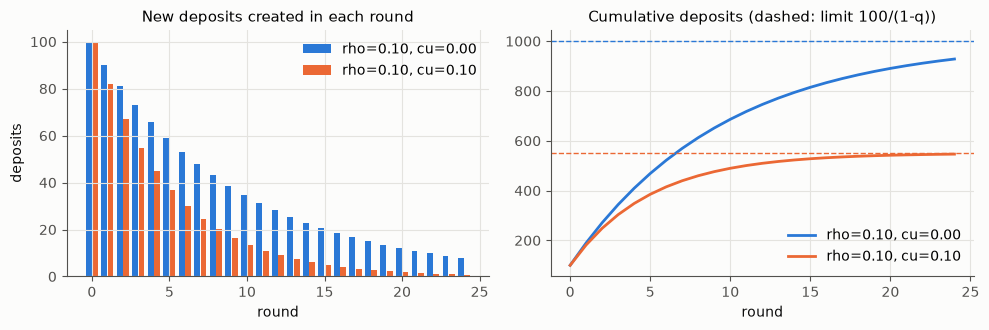

rho=0.10, cu=0.00: money multiplier M/H = 1/(rho+cu) = 10.00
rho=0.10, cu=0.10: money multiplier M/H = 1/(rho+cu) = 5.00
rho=0.10, cu=0.30: money multiplier M/H = 1/(rho+cu) = 2.50


In [2]:
# 1 巡ごとの新規預金(初回 100)。ρ だけの場合と、タンス預金 cu がある場合
rounds = np.arange(0, 25)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for k, (rho, cu) in enumerate([(0.10, 0.0), (0.10, 0.10)]):
    q = (1 - rho) / (1 + cu)            # 1 巡で次の預金になる割合
    dep = 100 * q ** rounds
    axes[0].bar(rounds + (k - 0.5) * 0.4, dep, width=0.38, color=PAL[k],
                label=f'rho={rho:.2f}, cu={cu:.2f}')
    axes[1].plot(rounds, np.cumsum(dep), color=PAL[k], label=f'rho={rho:.2f}, cu={cu:.2f}')
    axes[1].axhline(100 / (1 - q), color=PAL[k], lw=1, ls='--')
axes[0].set(title='New deposits created in each round', xlabel='round', ylabel='deposits')
axes[1].set(title='Cumulative deposits (dashed: limit 100/(1-q))', xlabel='round')
for ax in axes:
    ax.legend()
plt.tight_layout(); plt.show()
for rho, cu in [(0.10, 0.0), (0.10, 0.10), (0.10, 0.30)]:
    print(f'rho={rho:.2f}, cu={cu:.2f}: money multiplier M/H = 1/(rho+cu) = {1/(rho+cu):.2f}')

**図 1**: 左は各巡で新しく生まれる預金、右はその累計。破線が極限。タンス預金 cu があると一巡ごとの漏れが増え、累計の上限は 1000 から約 550 に下がる。最後の出力のとおり、乗数 $1/(\rho+cu)$ は cu=0.3 で 2.5 まで下がる。

## 2. 銀行の二つの制度: 量の制度と金利の制度

前節の話は、中央銀行がベースマネー $H$ の量を決め、銀行がその枠の中で貸す世界(**量の制度**)の話である。金本位制や、日本でも 1990 年代ごろまでの教科書的な説明がこれに近い。

ところが現代の多くの中央銀行は、量ではなく**政策金利**を決め、準備預金は銀行が必要とする分だけ供給する(**金利の制度**)。この世界では、銀行は先に貸し出し、貸出が預金を作り、必要な準備は後から調達する(McLeay, Radia and Thomas 2014; Werner 2014)。米国は 2020 年に法定準備率をゼロにし、日本の準備率もごく小さい。ここでは、**貸出の量を止めているのは準備の量ではない。** 止めているのは次のものである。

- 借り手の意欲: 借りて投資して、利払い以上に稼げる見込みがあるか。
- 担保: 借り手の資産(株式的富など)の価値。
- 銀行の健全性: 貸倒れで資本が減れば、貸せなくなる。

| | 量の制度 | 金利の制度 |
|---|---|---|
| 中央銀行が決めるもの | ベースマネー $H$ | 政策金利 $r$ |
| 準備預金 | 量が固定され、貸出の上限になる | 求めに応じて供給される |
| 法定準備率 ρ の効き方 | 信用の量の上限 $H/(\rho+cu)$ を直接決める | 無利子の準備を持つコストとして貸出金利を少し上げるだけ |
| タンス預金 cu の効き方 | 準備を吸い取り、信用を締める | 中央銀行が現金を出すだけで、信用は締まらない |

「信用創造を律するのは法定準備率だけではないか」という直観は、**量の制度では正しく、金利の制度では正しくない**。この区別は、後でモデルの中で実験して確かめる(第 8・9 節)。

## 3. v5 を式で読む

「信用創造ダイナミクス v5」(以下 v5)は、次の 5 つの量の動きを追うモデルである。

| 記号 | 意味 |
|---|---|
| $C$ | 信用量(貸出の残高) |
| $K$ | 在庫(物的資本だけでなく、研究・知識・組織などの蓄積を含む広い「在庫」) |
| $E$ | 株式的富(在庫が将来生む価値を、金利で割り引いた現在価値) |
| $Y$ | 所得 |
| $\Phi$ | 分配集中度(利払いが所得に占める割合) |

1 期(時間幅 $dt=0.1$)ごとの計算は次のとおり。添字のない量は今期、$Y_{-1}$ は前期の値。

$$
\begin{aligned}
\text{stress} &= \max\!\Big(0,\,-\frac{E_{\rm cur}-E_{-1}}{E_{-1}}\Big),\quad E_{\rm cur}=\frac{K^\alpha}{r+\delta_0} &&\text{(株式的富の目減り)}\\
\delta_K &= \delta_0\,(1+\kappa\cdot\text{stress}) &&\text{(在庫維持能力の喪失: 崩れると損耗が増える)}\\
\Phi &= \frac{rC}{Y_{-1}} &&\text{(分配集中度)}\\
\rho_{\rm eff} &= \rho+\mu\max(0,\Phi-\theta),\quad s_{\rm eff}=s+\gamma\max(0,\Phi-\theta) &&\text{(タンス預金化と需要抑制)}\\
E &= \frac{K^\alpha}{r+\delta_K} &&\text{(株式的富)}\\
C_{\rm flow} &= \lambda\,E\,(1-\rho_{\rm eff}) &&\text{(新規の信用の流れ)}\\
Y &= \frac{C_{\rm flow}}{1+s_{\rm eff}+\delta_C(1-s_{\rm eff})} &&\text{(所得)}\\
C &\leftarrow C + (C_{\rm flow}-rC)\,dt,\qquad K \leftarrow K + (s_{\rm eff}Y-\delta_K K)\,dt
\end{aligned}
$$

所得の式は、「信用の流れ $C_{\rm flow}$ は、所得 $Y$、在庫の積み増し、消費側の損耗 $\delta_C(1-s_{\rm eff})Y$ のどれかに分かれる」という分け方と、「所得の $s_{\rm eff}$ の割合が在庫になる」という仮定を連立して解いたものである。

各部分の考え方は次のとおり。

- **株式的富 $E$**: 在庫は将来の価値を生む。それを金利 $r$(と損耗 $\delta$)で割り引いた現在価値が、企業の値打ち=株式の値打ちになる。永続企業という前提に立った、いわば「合法的なペテン」である。金利が上がれば $E$ は縮む。
- **$\alpha<1$**: v4 までは $E=K/(r+\delta)$ で、在庫を積むほど $E$ が比例して増えた。そのため貯蓄率を上げると爆発的に成長し、$E$ が $C$ を大きく超えてしまった。$\alpha<1$ で収益逓減を入れて、これを抑えた。
- **信用の流れ $C_{\rm flow}=\lambda E(1-\rho_{\rm eff})$**: 株式的富が担保になって信用が生まれる。準備率の分は貸せない。
- **二つの漏れ**: 利払いが所得に比べて重くなる($\Phi$ が閾値 $\theta$ を超える)と、人々が信用の仕組みから降り始める。銀行に預けない(タンス預金化して $\rho_{\rm eff}$ が上がる)し、使わない(需要が抑えられて $s_{\rm eff}$ が上がる)。

まず、元の JavaScript を Python に忠実に移す。

In [3]:
import numpy as np

V5_DEFAULT = dict(r=0.05, rho=0.10, s=0.20, d0=0.04, kappa=3.0, dC=0.05,
                  theta=0.25, mu=0.60, lam=0.25, gam=0.40, alpha=0.70, T=150,
                  C0=10.0, K0=10.0, Y0=1.0, smooth=0.0)


def ramp(x, w):
    """max(0, x)。w>0 なら幅 w の softplus で滑らかにする。"""
    if w <= 0:
        return max(0.0, x)
    return w * np.logaddexp(0.0, x / w)


def simulate_v5(**kw):
    """credit_simulation_v5.html の simulate() の忠実な移植(dt=0.1 のオイラー法)。"""
    p = {**V5_DEFAULT, **kw}
    eps = 1e-8
    C, K = p['C0'], p['K0']
    E_prev = K ** p['alpha'] / (p['r'] + p['d0'] + eps)
    Y_prev = p['Y0']  # JS 版の初期値は 1(h.Y が空のとき)
    keys = ['C', 'K', 'Y', 'E', 'Phi', 'dK', 'seff', 'rhoeff', 'cons', 'dk2', 'Cflow']
    h = {k: [] for k in keys}
    for t in range(int(p['T'])):
        E_cur = K ** p['alpha'] / (p['r'] + p['d0'] + eps)
        stress = max(0.0, -(E_cur - E_prev) / (abs(E_prev) + eps))
        dK = p['d0'] * (1 + p['kappa'] * stress)
        loss_K = dK * K
        Phi = p['r'] * C / max(Y_prev, eps)
        rho_eff = min(p['rho'] + p['mu'] * ramp(Phi - p['theta'], p['smooth']), 0.99)
        s_eff = min(p['s'] + p['gam'] * ramp(Phi - p['theta'], p['smooth']), 0.95)
        E = K ** p['alpha'] / (p['r'] + dK + eps)
        C_flow = p['lam'] * E * (1 - rho_eff)
        dC2 = C_flow - p['r'] * C
        Y = C_flow / max(1 + s_eff + p['dC'] * (1 - s_eff), eps)
        cons = (1 - s_eff) * Y
        deltaK = s_eff * Y - loss_K
        for k, v in zip(keys, [C, K, Y, E, Phi, dK, s_eff, rho_eff, cons, deltaK, C_flow]):
            h[k].append(v)
        E_prev = E
        Y_prev = Y
        C = max(C + dC2 * 0.1, 0.01)
        K = max(K + deltaK * 0.1, 0.01)
    return {k: np.array(v) for k, v in h.items()}

移植が正しいことを、v5 の分析レポートの表と突き合わせて確かめる(α を動かした表 A、金利・準備率を動かした表 D)。レポートの値は、α=0.7 で $Y=25.3$、r=0.08 で $Y=0.107$、ρ=0.40 で $Y=0.115$ などである。

In [4]:
print('Table A (gamma=0):  alpha ->  Y_final  K_final  C_final  E_final')
for a in [1.0, 0.9, 0.8, 0.7, 0.6, 0.5]:
    h = simulate_v5(alpha=a, gam=0)
    print(f'   {a:.2f}  {h["Y"][-1]:10.1f} {h["K"][-1]:8.1f} {h["C"][-1]:8.1f} {h["E"][-1]:8.1f}')
print('Table D (defaults):  Y_final  K_final  E_final  Phi_final')
for lab, kw in [('base r=0.05', {}), ('r=0.08', dict(r=0.08)), ('r=0.10', dict(r=0.10)),
                ('rho=0.20', dict(rho=0.2)), ('rho=0.30', dict(rho=0.3)), ('rho=0.40', dict(rho=0.4))]:
    h = simulate_v5(**kw)
    print(f'   {lab:12s} {h["Y"][-1]:8.3f} {h["K"][-1]:7.1f} {h["E"][-1]:7.1f} {h["Phi"][-1]:8.3f}')

Table A (gamma=0):  alpha ->  Y_final  K_final  C_final  E_final
   1.00      4077.9   2022.7  12213.1  22474.0
   0.90       329.5    290.8   1708.9   1832.3
   0.80        71.8     98.1    551.9    435.6
   0.70        25.3     48.8    258.3    168.9
   0.60        11.5     30.0    147.4     85.5
   0.50         5.8     21.0     94.3     50.9
Table D (defaults):  Y_final  K_final  E_final  Phi_final
   base r=0.05    27.838    61.0   197.5    0.497
   r=0.08          0.107    27.1    83.8   50.705
   r=0.10          0.056    13.4    43.9   34.744
   rho=0.20       19.729    50.0   171.8    0.547
   rho=0.30        9.279    39.5   145.7    0.801
   rho=0.40        0.115    19.7    89.5   30.837


すべて一致した。続いて、デフォルト設定で HTML 版と同じ 150 期を走らせる。

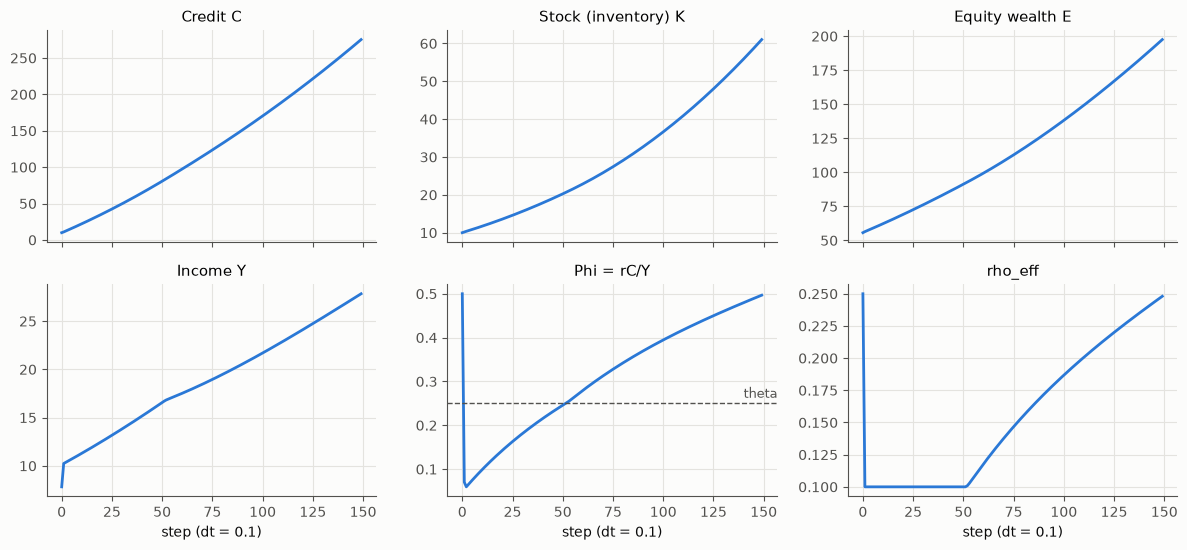

In [5]:
h = simulate_v5()
t = np.arange(len(h['Y']))
fig, axes = plt.subplots(2, 3, figsize=(12, 5.6), sharex=True)
for ax, (k, title) in zip(axes.flat, [('C', 'Credit C'), ('K', 'Stock (inventory) K'), ('E', 'Equity wealth E'),
                                      ('Y', 'Income Y'), ('Phi', 'Phi = rC/Y'), ('rhoeff', 'rho_eff')]):
    ax.plot(t, h[k], color=PAL[0])
    ax.set_title(title)
axes[1, 1].axhline(0.25, color=INK2, lw=1, ls='--')
axes[1, 1].annotate('theta', (140, 0.25), xytext=(0, 4), textcoords='offset points', color=INK2, fontsize=9)
for ax in axes[1]:
    ax.set_xlabel('step (dt = 0.1)')
plt.tight_layout(); plt.show()

**図 2**: v5 のデフォルト設定(T=150)。信用 $C$、在庫 $K$、株式的富 $E$、所得 $Y$ がそろって伸び、HTML 版の判定は「✅ 安定成長」になる。ただし下段中央の $\Phi$ を見ると、50 期ごろに閾値 θ=0.25(破線)を超え、その後も上がり続けている。そのため実効準備率 $\rho_{\rm eff}$(右下)も、法定の 0.10 から 0.25 近くまで上がっている。最初の数期に $\Phi$ が 0.5 から急落しているのは、前期の所得の初期値を $Y_{-1}=1$ と置いたためで、意味のある動きではない。

## 4. v5 を長く走らせる: 崩壊は必ず来る

図 2 で $\Phi$ が上がり続けていたのが気になる。そこで同じ設定のまま、もっと長く(600 期、さらに 3000 期)走らせてみる。

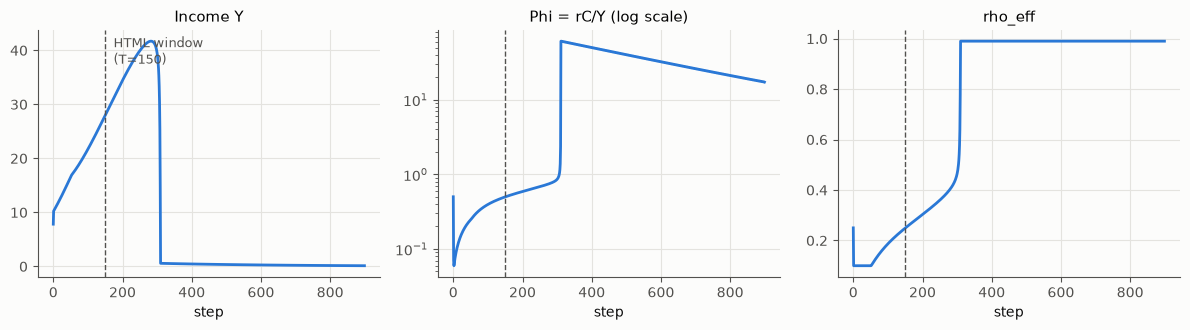

T=  150: Y=  27.838  C=  275.3  Phi=  0.497  rho_eff=0.248
T=  300: Y=  39.891  C=  681.7  Phi=  0.848  rho_eff=0.459
T=  600: Y=   0.270  C=  175.3  Phi= 32.234  rho_eff=0.990
T= 3000: Y=   0.003  C=    0.2  Phi=  2.574  rho_eff=0.990


In [6]:
h = simulate_v5(T=900)
t = np.arange(len(h['Y']))
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharex=True)
for ax, (k, title) in zip(axes, [('Y', 'Income Y'), ('Phi', 'Phi = rC/Y (log scale)'), ('rhoeff', 'rho_eff')]):
    ax.plot(t, h[k], color=PAL[0])
    ax.axvline(150, color=INK2, lw=1, ls='--')
    ax.set_title(title); ax.set_xlabel('step')
axes[0].annotate('HTML window\n(T=150)', (150, h['Y'].max() * 0.9), xytext=(6, 0),
                 textcoords='offset points', fontsize=9, color=INK2)
axes[1].set_yscale('log')
plt.tight_layout(); plt.show()
for T in [150, 300, 600, 3000]:
    h = simulate_v5(T=T)
    print(f'T={T:5d}: Y={h["Y"][-1]:8.3f}  C={h["C"][-1]:7.1f}  Phi={h["Phi"][-1]:7.3f}  rho_eff={h["rhoeff"][-1]:.3f}')

**図 3**: デフォルト設定を長く走らせると、$Y$ は 280 期ごろまで伸びたあと、300 期を過ぎたところで一気にほぼ 0 まで崩れる。$\rho_{\rm eff}$ は上限の 0.99 に張り付き、二度と戻らない。HTML 版の 150 期(破線)の時点では、まだ崩壊の手前だっただけである。

なぜ必ず崩れるのか。定常状態(すべての量が動かなくなった状態)を考えると、理由が一行でわかる。

信用が増えも減りもしない($\Delta C=0$)なら、$C_{\rm flow}=rC$ である。そして $Y=C_{\rm flow}/D$、ただし $D=1+s_{\rm eff}+\delta_C(1-s_{\rm eff})$ だから、

$$
\Phi^* = \frac{rC}{Y} = \frac{C_{\rm flow}}{Y} = D = 1+s_{\rm eff}+\delta_C(1-s_{\rm eff}) \;\ge\; 1 .
$$

**定常状態の分配集中度は、必ず 1 以上になる。** 一方、閾値 θ は 0.05〜0.60 の範囲でしか動かせない。だから長期的には必ず $\Phi>\theta$ になり、タンス預金化と需要抑制が働き続ける。デフォルト値では

$$
\Phi^*=1.847,\quad s^*_{\rm eff}=0.839,\quad \rho^*_{\rm eff}=0.10+0.6\times(1.847-0.25)=1.058>1
$$

となり、貸し出せる割合 $1-\rho_{\rm eff}$ が負になってしまう。つまり、崩壊しない定常状態はそもそも存在しない。

**$\Phi^*\ge1$ になる理由が、v5 のいちばん大事な弱点である。** v5 では、利払い $rC$ は信用残高 $C$ から差し引かれて消えるだけで、誰の所得にもならない。定常状態では新しい信用がすべて利払いに吸い込まれ、その利払いは経済から消える。「金利は誰かの所得になり、結局は経済に戻る」という出発点の直観が、モデルに入っていないのである。

この解析解が正しいことは、崩壊しない定常状態が存在する設定(μ と γ を小さくした場合)で、長く走らせた結果と比べて確かめられる。

In [7]:
def v5_steady_state(**kw):
    """v5 の内点定常状態(ΔC=0, ΔK=0, stress=0)を解析的に求める。

    ΔC=0 より C_flow = rC、Y = C_flow/D なので Φ* = rC/Y = D(s_eff)。
    D = 1 + s_eff + δC(1−s_eff) ≥ 1 なので、Φ* は必ず 1 以上になる。
    """
    p = {**V5_DEFAULT, **kw}
    # Φ = D, s_eff = s + γ max(0, Φ−θ) の不動点(クリップ込み)を反復で解く
    Phi = 1.0
    for _ in range(500):
        s_eff = min(p['s'] + p['gam'] * max(0.0, Phi - p['theta']), 0.95)
        Phi_new = 1 + s_eff + p['dC'] * (1 - s_eff)
        if abs(Phi_new - Phi) < 1e-13:
            break
        Phi = 0.5 * Phi + 0.5 * Phi_new
    rho_eff_raw = p['rho'] + p['mu'] * max(0.0, Phi - p['theta'])
    rho_eff = min(rho_eff_raw, 0.99)
    a, d0, r = p['alpha'], p['d0'], p['r']
    # K = s_eff Y/δ0, E = K^α/(r+δ0), Y = λE(1−ρ_eff)/D
    Y = (p['lam'] * (1 - rho_eff) * (s_eff / d0) ** a / (Phi * (r + d0))) ** (1 / (1 - a))
    K = s_eff * Y / d0
    return dict(Phi=Phi, s_eff=s_eff, rho_eff_raw=rho_eff_raw, rho_eff=rho_eff,
                Y=Y, K=K, C=Phi * Y / r, E=K ** a / (r + d0))

In [8]:
print('setting                 Phi*   s_eff*  rho_eff(raw)   Y* (analytic)   Y (simulated, T=8000)')
for kw in [dict(), dict(mu=0, gam=0), dict(mu=0.1), dict(mu=0.3, gam=0)]:
    ss = v5_steady_state(**kw)
    h = simulate_v5(T=8000, **kw)
    print(f'{str(kw):22s} {ss["Phi"]:6.3f} {ss["s_eff"]:7.3f} {ss["rho_eff_raw"]:10.3f} {ss["Y"]:14.3f} {h["Y"][-1]:16.3f}')

setting                 Phi*   s_eff*  rho_eff(raw)   Y* (analytic)   Y (simulated, T=8000)
{}                      1.847   0.839      1.058          0.001            0.001
{'mu': 0, 'gam': 0}     1.240   0.200      0.100        442.579          442.523
{'mu': 0.1}             1.847   0.839      0.260       1735.014         1732.908
{'mu': 0.3, 'gam': 0}   1.240   0.200      0.397        116.477          116.477


デフォルト設定は $\rho^*_{\rm eff}>1$ なので、崩壊しない定常状態がない(解析解も 0 に近い値になる)。μ や γ を小さくした設定では、解析解と長期シミュレーションが一致する。

### 「臨界金利」は観察期間が生んだもの

v5 の分析レポートは、金利 $r$ がおよそ 0.08〜0.09 を超えると崩壊する、という「臨界金利」を報告していた。ところが上で見たとおり、デフォルト設定では $r=0.05$ でも崩壊する。そこで、それぞれの金利で「何期目に崩壊するか」を測ってみる。

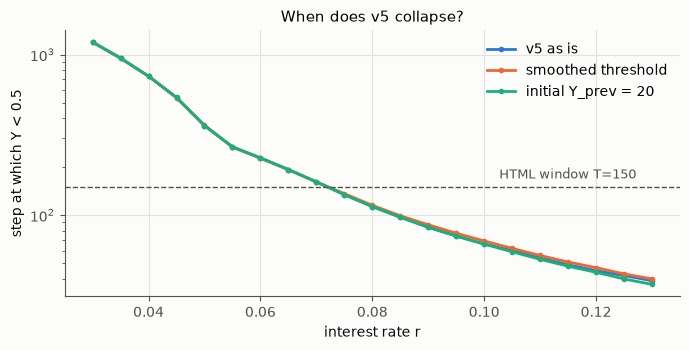

In [9]:
def collapse_step(h, thr=0.5):
    idx = np.where(h['Y'] < thr)[0]
    return idx[0] if len(idx) else np.nan


rs = np.round(np.arange(0.03, 0.131, 0.005), 3)
fig, ax = plt.subplots(figsize=(7, 3.6))
for k, (lab, kw) in enumerate([('v5 as is', {}), ('smoothed threshold', dict(smooth=0.1)),
                               ('initial Y_prev = 20', dict(Y0=20.0))]):
    steps = [collapse_step(simulate_v5(r=r, T=3000, **kw)) for r in rs]
    ax.plot(rs, steps, color=PAL[k], marker='o', ms=3, label=lab)
ax.axhline(150, color=INK2, lw=1, ls='--')
ax.annotate('HTML window T=150', (rs[-1], 150), xytext=(-110, 6), textcoords='offset points',
            fontsize=9, color=INK2)
ax.set(xlabel='interest rate r', ylabel='step at which Y < 0.5', yscale='log',
       title='When does v5 collapse?')
ax.legend(); plt.tight_layout(); plt.show()

**図 4**: 縦軸は崩壊($Y<0.5$)が起きる期(対数目盛)。金利が上がるほど崩壊は早く来るが、**どの金利でも崩壊は来る**。150 期の窓(破線)の中に崩壊が入るのが $r\approx0.08$ からなので、それが「臨界金利」に見えていた。閾値の折れ線を幅 0.1 のなめらかな曲線(softplus)に替えても、前期所得の初期値を 20 に替えても、ほとんど変わらない(3 本の線が重なっている)。**折れ線の形も初期値も本質ではなく、本質は「利子が経済から消える」構造にある。**

## 5. v5 の定常状態が安定である条件

μ と γ が小さければ、崩壊しない定常状態が存在する。では、それは安定なのか。μ を少しずつ上げると、定常状態は存在していても、ある所から崩れ始める。

直観的には次のループがある。

$$
Y\downarrow \;\Rightarrow\; \Phi=\frac{rC}{Y}\uparrow \;\Rightarrow\; \rho_{\rm eff}\uparrow \;\Rightarrow\; C_{\rm flow}\downarrow \;\Rightarrow\; Y\downarrow
$$

$C$ と $K$ を固定して、前期の所得 $Y_{-1}$ から今期の所得 $Y$ への 1 期の反応だけを見る。$Y=A\,(1-\rho_{\rm eff})$($A$ は今期の $\lambda E/D$)、$\rho_{\rm eff}=\rho+\mu(rC/Y_{-1}-\theta)$ だから

$$
\frac{\partial Y}{\partial Y_{-1}} = A\mu\frac{rC}{Y_{-1}^2} = \frac{\mu\,\Phi^*}{1-\rho^*_{\rm eff}}\quad(\text{定常状態で } Y=Y_{-1},\ A=Y/(1-\rho_{\rm eff})).
$$

このループの強さ(ゲイン)が 1 を超えると、所得の小さな落ち込みが前期より大きな落ち込みを呼び、崩壊に向かう。よって安定の条件は、おおよそ

$$
\boxed{\;\frac{\mu\,\Phi^*}{1-\rho^*_{\rm eff}} < 1\;}
$$

である。これを、モデル全体(状態 = $C, K, Y_{-1}, E_{-1}$)の 1 期写像のヤコビアンの固有値で確かめる。固有値の絶対値の最大(スペクトル半径)が 1 未満なら、定常状態は局所的に安定である。

In [10]:
def v5_step(state, p):
    """v5 の 1 ステップ写像(状態 = C, K, 前期 Y, 前期 E)。クリップは定常点の近傍では効かないものとする。"""
    C, K, Yp, Ep = state
    eps = 1e-8
    E_cur = K ** p['alpha'] / (p['r'] + p['d0'] + eps)
    stress = max(0.0, -(E_cur - Ep) / (abs(Ep) + eps))
    dK = p['d0'] * (1 + p['kappa'] * stress)
    Phi = p['r'] * C / Yp
    rho_eff = p['rho'] + p['mu'] * max(0.0, Phi - p['theta'])
    s_eff = p['s'] + p['gam'] * max(0.0, Phi - p['theta'])
    E = K ** p['alpha'] / (p['r'] + dK + eps)
    C_flow = p['lam'] * E * (1 - rho_eff)
    Y = C_flow / (1 + s_eff + p['dC'] * (1 - s_eff))
    return np.array([C + (C_flow - p['r'] * C) * 0.1,
                     K + (s_eff * Y - dK * K) * 0.1, Y, E])


def v5_spectral_radius(**kw):
    """内点定常状態での 1 ステップ写像のヤコビアンの最大固有値の絶対値(1 未満なら局所安定)。"""
    p = {**V5_DEFAULT, **kw}
    ss = v5_steady_state(**kw)
    x0 = np.array([ss['C'], ss['K'], ss['Y'], ss['E']])
    J = np.zeros((4, 4))
    for j in range(4):
        # stress は max(0, ·) の折れ目にあるので、stress が立たない側(前期 E は下げる側)の片側差分を取る
        h = 1e-6 * x0[j] * (-1 if j == 3 else 1)
        J[:, j] = (v5_step(x0 + np.eye(4)[j] * h, p) - v5_step(x0, p)) / h
    return max(abs(np.linalg.eigvals(J)))

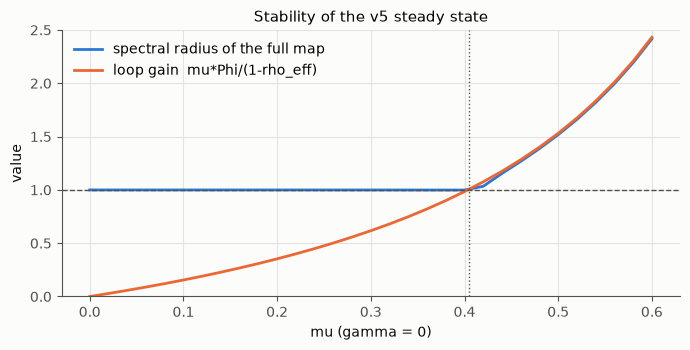

critical mu = 0.405


In [11]:
mus = np.linspace(0.0, 0.6, 31)
rad, gain = [], []
for m in mus:
    ss = v5_steady_state(mu=m, gam=0)
    rad.append(v5_spectral_radius(mu=m, gam=0))
    gain.append(m * ss['Phi'] / (1 - ss['rho_eff']))
mu_c = brentq(lambda m: v5_spectral_radius(mu=m, gam=0) - 1, 0.3, 0.5)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(mus, rad, color=PAL[0], label='spectral radius of the full map')
ax.plot(mus, gain, color=PAL[1], label='loop gain  mu*Phi/(1-rho_eff)')
ax.axhline(1, color=INK2, lw=1, ls='--'); ax.axvline(mu_c, color=INK2, lw=1, ls=':')
ax.set(xlabel='mu (gamma = 0)', ylabel='value', title='Stability of the v5 steady state', ylim=(0, 2.5))
ax.legend(); plt.tight_layout(); plt.show()
print(f'critical mu = {mu_c:.3f}')

**図 5**: 青はモデル全体のスペクトル半径、オレンジは上で求めたループゲイン。μ が小さいうちスペクトル半径は 1 のわずかに下にある。これは、成長がゆっくり止まっていく遅い動きの分である。ループゲインが 1 を超える所(μ≈0.405、点線)で、スペクトル半径も 1 を超える。**v5 の安定性は、ほぼこの 1 本のループで決まっている。**

ここまでのまとめ:

- v5 では利払いが経済から消えるので、定常状態の $\Phi$ が必ず 1 以上になる。閾値 θ<1 の設定では、長期的には必ずタンス預金化が働き続ける。
- デフォルト設定には崩壊しない定常状態がない。「安定成長」に見えたのは 150 期という窓のせいで、「臨界金利」も窓が作ったものだった。
- 崩壊しない定常状態があっても、ループゲイン $\mu\Phi/(1-\rho_{\rm eff})$ が 1 を超えると崩れる。

## 6. Φ と ρ_eff は正しいか: 導き直しと批判

v5 の式

$$\Phi=\frac{rC}{Y},\qquad \rho_{\rm eff}=\rho+\mu\max(0,\Phi-\theta),\qquad s_{\rm eff}=s+\gamma\max(0,\Phi-\theta)$$

は、議論の中で一番飛躍があった所である。「利払いが重くなりすぎると、人々が信用の仕組みから降りる」という行動を、準備率の上昇として圧縮して表したものだった。この節では、この式を**別の仮定から導き直す**。そうすると、どこが正しく、どこを直すべきかがはっきりする。結論を先に言うと、**式の形はほぼ正しい。ただし、記号の意味と、効く条件が違う。**

### 6.1 Φ は「分配集中度」というより「利払い負担率」

$\Phi=rC/Y$ は、所得のうち利払いに回る割合である。実証研究でいう**債務返済比率**(debt service ratio, DSR: 利払いと元本返済の合計を所得で割ったもの)に当たる。DSR は銀行危機の直前に上がる、短期の先行指標として知られている(Drehmann and Juselius 2013)。

これが「分配の集中」になるのは、**利払いを受け取る側が、受け取ったお金をあまり使わない人々(金利生活者・富裕層)であるとき**に限られる。誰が受け取るかを言わなければ、Φ は単に「負担の重さ」であって「集中」ではない。この区別は 6.4 で効いてくる。

### 6.2 ρ_eff = ρ + cu: タンス預金化は、量の制度では文字どおり実効準備率を上げる

第 1 節で見たとおり、量の制度では信用の上限は $H/(\rho+cu)$ で決まる。**準備率 ρ とタンス預金率 cu は、まったく同じ場所に入る。** だから

$$\rho_{\rm eff}=\rho+cu$$

と書くのは比喩ではない。量の制度では、これは正確な式である。1930〜33 年の米国の大恐慌では、銀行への不信で人々が預金を引き出し(cu の上昇)、銀行は準備を厚くした。その結果、ベースマネーは増えていたのに、マネーの量は約 3 分の 1 減った(Friedman and Schwartz 1963)。「タンス預金化が実効準備率を上げて信用を収縮させる」という v5 の直観は、この歴史とよく合う。

ただし、第 2 節で述べたとおり、**金利の制度ではこの経路は働かない。** 人々が現金を引き出しても、中央銀行が現金を出し、準備を補うだけである。この違いは第 9 節で実験する。

### 6.3 閾値 θ は自由パラメータではない: θ* = 利払い前の純利潤分配率

人々はいつ預金から現金に逃げるのか。銀行が危ないと感じたとき、つまり**貸倒れが出たとき**である。では、いつ貸倒れが出るのか。企業が利払いを払えなくなったときである。

企業の利潤を、所得 $Y$ に対する割合で書く。$\pi$ を利潤分配率(所得のうち企業に行く割合)、$\delta K/Y$ を損耗の割合とすると、

$$
\frac{\text{企業の純利潤}}{Y} = \underbrace{\pi-\frac{\delta K}{Y}}_{\theta^*\ (\text{利払い前の純利潤分配率})} - \underbrace{\frac{rL}{Y}}_{\Phi}
= \theta^*-\Phi .
$$

**企業の損失は $(\Phi-\theta^*)Y$ の正の部分で、これが貸倒れの元になる。** 現金への逃避 cu が、貸倒れの規模に比例して増えるとすると、

$$
\rho_{\rm eff} = \rho + cu_0 + \mu\cdot\max(0,\ \Phi-\theta^*)
$$

が出てくる。**v5 の式とまったく同じ形である。** 違いは、θ が自由に選ぶ定数ではなく、「利払い前の純利潤分配率」という観測できる量 θ* になることだ。そして先進国の集計値では、θ* は 0.1〜0.2 程度、Φ は数 % 程度なので、**経済全体で Φ>θ* になることはまずない。** 経済全体ではなく、一部の企業や部門で Φ>θ* になる所から危機は始まる。これが次の 6.4 につながる。

### 6.4 企業ごとのばらつきがあれば、折れ線はなめらかな曲線になる

企業 $i$ ごとに、利払い前の純利潤分配率 $\theta_i$ が違うとする。平均 $\bar\theta$、標準偏差 $\sigma$ の正規分布に従うとし、利払い負担 Φ は簡単のため共通とする。経済全体の損失は $\mathbb{E}[\max(0,\Phi-\theta_i)]$ で、これは閉じた式で書ける。

$$
\mathbb{E}[\max(0,\Phi-\theta_i)] = \sigma\,\big[z\,N(z)+n(z)\big],\qquad z=\frac{\Phi-\bar\theta}{\sigma}
$$

($N$ は標準正規分布の累積分布関数、$n$ はその密度)。σ→0 の極限では v5 の折れ線 $\max(0,\Phi-\bar\theta)$ に戻る。σ>0 では、平均的な企業がまだ黒字でも($\Phi<\bar\theta$)、一部の企業の損失が少しずつ現れる。

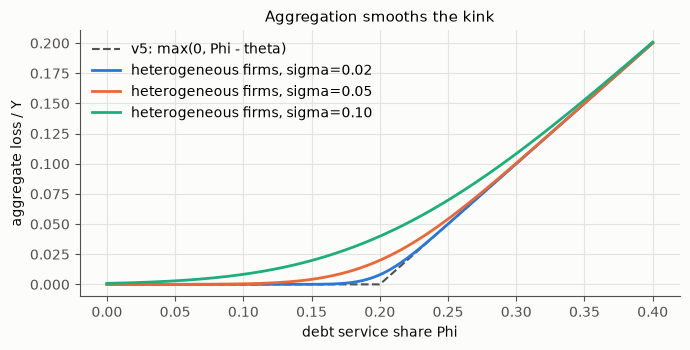

In [12]:
phi = np.linspace(0, 0.4, 400)
theta_bar = 0.2
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(phi, np.maximum(0, phi - theta_bar), color=INK2, lw=1.5, ls='--', label='v5: max(0, Phi - theta)')
for k, sig in enumerate([0.02, 0.05, 0.10]):
    z = (phi - theta_bar) / sig
    ax.plot(phi, sig * (z * norm.cdf(z) + norm.pdf(z)), color=PAL[k], label=f'heterogeneous firms, sigma={sig:.2f}')
ax.set(xlabel='debt service share Phi', ylabel='aggregate loss / Y', title='Aggregation smooths the kink')
ax.legend(); plt.tight_layout(); plt.show()

**図 6**: 破線が v5 の折れ線、色の線が企業のばらつきを入れた集計値。ばらつきが大きいほど、損失は早くから少しずつ立ち上がる。第 4 節で見たように、なめらかにしても v5 の結論は変わらない。それでも、**閾値は「経済全体で一斉に越える壁」ではなく、「弱い企業から順に越えていく分布」として理解する方が現実に近い。**

### 6.5 s_eff は閾値なしで出てくる: 階級による貯蓄性向の違い

需要が抑えられる経路($s_{\rm eff}$)も導き直せる。経済に二つの階級があるとする。賃金で暮らす労働者は所得の大半を使う(貯蓄性向 $s_w$ は小さい)。利子・配当で暮らす金利生活者はあまり使わない(貯蓄性向 $s_r$ は大きい)。経済全体の貯蓄率は、

$$
s_{\rm agg} = s_w + (s_r-s_w)\times(\text{金利生活者の所得の割合})
$$

となる。金利生活者の所得の割合には利払い Φ が含まれるので、**Φ が上がれば、閾値がなくても全体の貯蓄率は一次式で上がる。** これは Kaldor (1955) や Pasinetti (1962) の、階級別の貯蓄性向による分配理論と同じ構造である。最近では Mian, Straub and Sufi (2021) が「Indebted Demand(債務に縛られた需要)」と呼んでいる。富裕層の貯蓄が借り手への貸出になり、借り手の利払いがまた富裕層の所得になって貯蓄される。この繰り返しで需要が細り、金利が下がっていく、という議論である。

### 6.6 ここまでの判定

| v5 の要素 | 判定 |
|---|---|
| $\Phi=rC/Y$ | 量としては正しい(利払い負担率)。「集中」と呼べるのは、受け取り手の貯蓄性向が高いときだけ |
| $\rho_{\rm eff}=\rho+\mu\max(0,\Phi-\theta)$ | **量の制度では正しい形**($\rho+cu$、cu は貸倒れに反応)。θ は θ* = 利払い前の純利潤分配率と読むべき。金利の制度では、この経路はほぼ働かない |
| $s_{\rm eff}=s+\gamma\max(0,\Phi-\theta)$ | 階級の構成比の効果として、閾値なしの一次式で出る |
| 利払い $rC$ が消える | **ここが最大の問題。** 利子は金利生活者の所得として戻すべきで、そうしないと $\Phi^*\ge1$ と崩壊が必ず起きる |

次の節では、この判定をそのまま組み込んだモデルを作る。

## 7. 改良モデル: 利子が戻る二階級の信用循環モデル

v5 のよい所は残す。

- 株式的富 $E$ を、将来の利潤を金利で割り引いた価値として扱い、それが担保になる。
- 崩れるときに在庫の損耗が増える($\kappa$: 在庫維持能力の喪失)。

そのうえで、次の 4 点を直す。

1. **利子と配当は、金利生活者の所得として経済に戻る。**
2. **所得は需要で決まる**(労働者の消費 + 金利生活者の消費 + 投資 + 政府支出)。貯蓄がそのまま在庫になるのではなく、投資は企業が利潤を見て決め、貯蓄は所得の結果として決まる。
3. **銀行の二つの制度**(量の制度と金利の制度)を切り替えられるようにする。
4. **国家と労働**は、スイッチで足し引きできる部品にする。

すべてのお金の流れが「誰かの支出は誰かの収入」として帳尻が合うように作る。こうしたモデルを**ストック・フロー一貫(SFC)モデル**と呼ぶ(Godley and Lavoie 2007)。

### 7.1 部門と貸借

| | 企業 | 労働者 | 金利生活者 | 政府 | 合計 |
|---|---|---|---|---|---|
| 在庫・資本 $K$ | $+K$ | | | | $+K$ |
| 貸出 $L$ | $-L$ | | $+L$ | | 0 |
| 国債 $B$ | | | $+B$ | $-B$ | 0 |
| 株式 $E$ | $-E$ | | $+E$ | | 0 |

銀行は金利生活者の側にまとめた(預金と貸出は銀行を通るが、最終的な債権者は金利生活者)。

### 7.2 1 期ごとの計算: 式と、その読み方

1 期は $dt=0.1$ 年である。添字 $_{-1}$ は前の期の値を表す。以下の $r$ は、すべて中央銀行の**政策金利** $r_{cb}$(コードでは `r_cb`)のことで、国債の金利もこれに等しいとする。それぞれの記号の既定値と意味は、下のコードの `CM_DEFAULT` のコメントにある。

**(1) 貸出金利**

$$
r_L = \frac{r_{cb}+\text{spread}}{1-\rho} + \text{spread\_loss}\cdot\min(\text{貸倒れ率}_{-1},\,0.1)
$$

銀行は、預金を 1 受け入れるごとに、そのうち $\rho$ を利息のつかない準備として中央銀行に置かなければならない。残りの $1-\rho$ で、調達コスト $r_{cb}$ と利ざや spread を稼ぐ必要がある。そのため、貸出金利は $1/(1-\rho)$ 倍に割り増される。法定準備率 ρ は、この**「準備への税」として、量の制度でも金利の制度でも効く**。さらに、前の期に貸倒れが出ていれば、そのリスク分が上乗せされる(上乗せは貸倒れ率 10% で頭打ち)。

**(2) 株式的富**

$$
E = \frac{\Pi^e}{r_L+\text{prem}},\qquad \Pi^e \leftarrow \Pi^e + \frac{\Pi-\Pi^e}{\tau_e}\,dt
$$

$\Pi^e$ は、企業の純利潤 Π をゆっくり(時定数 $\tau_e=2$ 年)追いかける**期待利潤**である。株式的富は、この期待利潤が永遠に続くとして、貸出金利にリスクプレミアム prem を足した率で割り引いた現在価値になる(永続企業の前提)。

v5 の $E=K^\alpha/(r+\delta)$ との違いは、**在庫 K ではなく利潤を割り引く**ことにある。在庫があっても売れなければ(需要がなければ)利潤は出ず、$E$ も上がらない。コードでは、期待利潤が負のとき $E$ が 0 に近づくよう分子をなめらかに正にしている。また、割引率が 0 に近づいて $E$ が無限大にならないよう、分母に 0.5% の下駄を履かせてある。

**(3) 投資の希望**

$$
\frac{I^{\rm des}}{K} = \delta_0 + \underbrace{g_0 + g_1\,\frac{\Pi_{-1}}{K} + g_2\,(u_{-1}-0.85) + g_q\Big(\frac{E}{K}-q_{\rm ref}\Big)}_{\text{純投資率の希望 } g_{\rm net}}
$$

ここが一番わかりにくい所なので、項ごとに読む。

- $\delta_0$ は、平時にすり減る分(5%)を置き換えるための投資である。これだけなら資本は増えも減りもしない。
- $g_0=-0.02$ は、利潤がまったく出ないとき、企業が資本を年 2% ずつ縮めていく、という意味である。
- $g_1\,\Pi_{-1}/K$ は、**前の期の利潤率**(利払いと平時の損耗を引いた後の利潤を、資本で割ったもの)に応じて拡張する項である。$g_1=0.75$ なので、利潤率が 1% 上がると、純投資率が 0.75% 上がる。利潤は「儲かるから増やそう」という信号であると同時に、借りずに投資できる手元資金でもある。カレツキは、借入に頼るほどリスクが増すので、手元の利潤が投資の歯止めになると考えた(危険逓増の原理)。この項はそれを表している。基準の経路では利潤率が約 7.3% なので、$-0.02+0.75\times0.073\approx0.034$、つまり 3.4% の成長になる。
- $g_2\,(u_{-1}-0.85)$ は、設備がよく使われている(稼働率 $u$ が高い)ほど投資を増やす、いわゆる**加速度原理**の項である。既定値は $g_2=0$ にしてある。これを大きくすると、「売れる → 投資する → 所得が増えて売れる」の自己強化が強くなりすぎて、経済が発散しやすくなる(ハロッドの不安定性)。
- $g_q\,(E/K-q_{\rm ref})$ は**トービンの q** の項である(Tobin 1969)。市場が企業を、設備を買い直す費用より高く評価している($q=E/K$ が大きい)ほど、投資して設備を増やす価値がある。既定値は $g_q=0$ で、第 11 節でだけ 0.03 にする。

前の期の値を使うのは、企業が「前の期の決算を見て今期の投資を決める」ためである。今期の所得と投資を同時に決める計算を避ける意味もある。

**(4) 資金繰りと借入**

$$
\text{内部資金} = (1-\text{payout})\,\Pi_{-1} + \delta_0 K,\qquad
\Delta L = \mathrm{softmin}\Big(I^{\rm des}-\text{内部資金},\ \frac{\lambda(E+K)-L}{T_{\rm adj}}\Big)
$$

企業は、配当しなかった利潤と、減価償却で手元に残る分($\delta_0K$)で、まず投資を賄う。足りない分を借りる。ただし、借入の残高 $L$ は担保の価値 $\lambda(E+K)$($\lambda=0.6$)までしか持てない。株式的富が下がって担保の上限を割り込むと、右の項が負になり、$T_{\rm adj}=2$ 年かけて返済を迫られる。softmin は min をなめらかにしたもので、二つのうち厳しい方がほぼ効く。実際の投資は $I=\Delta L+\text{内部資金}$ で、借りられなかった分だけ希望より小さくなる。

**(5) 所得: 需要が決める**

$$
Y = \underbrace{c_w(1-\tau)\,\omega Y}_{\text{労働者の消費}} + \underbrace{c_r(1-\tau)\,(r_L L + r_{cb} B + \text{配当}) + c_v(L+B)}_{\text{金利生活者の消費}} + I + G
$$

- 労働者は、税引き後の賃金 $(1-\tau)\omega Y$ の 95% を使う。
- 金利生活者は、税引き後の利子・配当の 35% と、金融資産の 2% を使う。
- 配当は純利潤の 60% で、純利潤 $\Pi=(1-\omega)Y-\delta_0K-r_LL$ も $Y$ を含む。
- 政府支出は生産能力に比例する($G=g_G\,K/v$)。

右辺も $Y$ の一次式なので、$Y$ について解ける。解いた結果が $Y^d$(需要)である。

ただし、生産能力 $Y_p$ を超えては生産できない。$Y_p$ は資本で決まる $u_{\max}K/v$ で、労働を入れる場合は完全雇用の能力との小さい方になる。そこで、実現する所得は、「その所得のもとでの需要」と $Y_p$ のなめらかな min が、その所得自身に一致するように決める(反復で解く)。

生産能力に届いたときは、需要の一部が満たされない。満たされなかった分は消費から差し引く(買えなかった分は貯蓄に回る。強制貯蓄)。こうしておくと、届いたときも「生産 = 支出」の帳尻が合う。

**(6) 貸倒れ**

$$
CF = (1-\omega)Y - r_L L,\qquad \text{貸倒れ} = \min\big(0.5\cdot\max(0,-CF),\ 0.5\,L\big)
$$

利払い後の営業キャッシュフロー $CF$ が負になる(利払いができない)と、その半分が貸倒れになり、借入残高から消える(1 年に残高の半分が上限)。貸倒れ率は、次の期の貸出金利の上乗せと、現金選好 cu を押し上げる。

**(7) ストックの更新**

$$
\begin{aligned}
K &\leftarrow K + (I-\delta K)\,dt,\qquad \delta=\delta_0\,(1+\kappa\cdot\text{stress}_E),\quad \text{stress}_E=\max\Big(0,-\frac{\Delta E/E}{dt}\Big)\\
L &\leftarrow L + (\Delta L - \text{貸倒れ})\,dt,\qquad B \leftarrow B + (G + r_{cb}B - \text{税})\,dt
\end{aligned}
$$

株式的富が目減りしているときだけ、実際の損耗 δ が平時の δ0 より大きくなる。v5 の「在庫維持能力の喪失」をそのまま引き継いだ部分である。この余分な損耗は、物が本当に失われることを表し、置き換え投資の対象にはしない。そのため、投資の希望の式には δ ではなく δ0 が入っている。

### 7.3 量の制度: なぜコードの違いが一か所だけなのか

量の制度と金利の制度の違いは、コードでは「量の制度のときだけ、借入にもう一つ上限をかける」一か所だけである。その理由を式で示す。

銀行(全体)の貸借対照表を考える。簡単のため、国債 $B$ はすべて銀行が持っているとする。

$$
\underbrace{L + B + R}_{\text{資産: 貸出・国債・準備}} = \underbrace{M}_{\text{負債: 預金}},\qquad R=\rho M\ (\text{法定準備ちょうど}),\qquad \text{現金} = cu\cdot M .
$$

中央銀行が出したお金(ベースマネー)は、準備か、人々の手元の現金のどちらかにある。

$$
H = R + \text{現金} = (\rho+cu)\,M \quad\Longrightarrow\quad M=\frac{H}{\rho+cu},\qquad L+B = (1-\rho)M = \frac{(1-\rho)\,H}{\rho+cu} .
$$

- **金利の制度**では、中央銀行は政策金利 $r_{cb}$ を決め、銀行が必要とするだけ $H$ を出す。$H$ が $L+B$ に合わせて動くので、この式は「$H$ がいくら必要か」を決めるだけで、貸出を制約しない。だからコードには何も書く必要がない。
- **量の制度**では、$H$ は中央銀行が決めた経路(年 $g_H$ で伸びる)に従い、貸出の都合では動かない。この式が**銀行の信用の上限**になる。

$$
L + B \le \text{credit\_cap} = \frac{(1-\rho)\,H}{\rho+cu},\qquad
\Delta L \leftarrow \mathrm{softmin}\Big(\Delta L,\ \frac{\text{credit\_cap}-L-B}{T_{\rm adj}}\Big)
$$

これがコードの違う一か所である。ここから三つのことが読み取れる。

1. ρ が上がっても、cu(タンス預金)が上がっても、上限は同じように下がる。だから $\rho_{\rm eff}=\rho+cu$ になる。
2. 政府の赤字で $B$ が増えると、民間への貸出に使える枠が減る(**量の制度でのクラウディング・アウト**)。
3. 上限は**残高の天井**であって、毎期の信用の流れを削るものではない。初期値では上限がちょうど今の残高に等しくなるよう $H$ を置いている。$H$ が経済の成長(3.4%)より速く伸びる($g_H=5\%$)設定では、平時は天井に余裕があり、何も効かない。天井が効くのは、cu の急上昇などで天井の方が下がってきたときだけである。

3 番目は、v5 との大事な違いでもある。v5 では、実効準備率が毎期の信用の流れに $C_{\rm flow}=\lambda E(1-\rho_{\rm eff})$ という形で掛かり、流れを常に一定の割合で削っていた。準備の制約は本来、天井にぶつかるまでは効かない「上限」として入るべきものである。

### 7.4 観測する量と、ミンスキーの分類

v5 の Φ, θ, $s_{\rm eff}$, $\rho_{\rm eff}$ は、このモデルでは**仮定ではなく、結果として観測する量**になる。

- $\Phi=r_LL/Y$
- $\theta^*=((1-\omega)Y-\delta_0K)/Y$
- $s_{\rm agg}$ = 経済全体の貯蓄率
- $\rho_{\rm eff}=\rho+cu$

企業の資金繰りは、Minsky (1986) にならって 3 つに分類して記録する。基準にするのは、平時の維持更新をした後の営業キャッシュフロー $OCF=(1-\omega)Y-\delta_0K$ である。借入の平均の返済期間を 10 年と見て、元本の 1/10 を毎年の返済額とする。

- **ヘッジ**: $OCF \ge r_LL + L/10$。利払いに加えて、残高の 1/10 **以上**の元本を毎年返せる。
- **投機的**: $r_LL \le OCF < r_LL + L/10$。利払いはできるが、元本は借り換えに頼る。
- **ポンジ**: $OCF < r_LL$。利払いさえできず、借りて払うしかない。

`simulate_cm` が毎期記録する量は、コードの `CM_KEYS` の各行のコメントに説明してある。

In [13]:
# Claude 版「信用循環モデル」: ストック・フロー一貫(SFC)の二階級モデル。
# 部門: 企業(借りて K を積む)、労働者(賃金を消費)、金利生活者(利子・配当を受け取り、貯蓄しやすい)、
#       銀行(貸出が預金を作る。準備率 ρ と現金選好 cu で量的上限がかかりうる)、政府(G・税・国債)。
CM_DEFAULT = dict(
    T=150.0, dt=0.1,
    v=2.5,          # 資本係数: 生産能力 Y_p = K/v
    u_max=1.1,      # 資本稼働率の上限(能力を超えた需要は実現せず「価格圧力」になる)
    omega=0.65,     # 賃金分配率(利潤分配率 π = 1 − ω)
    d0=0.05,        # 平時の損耗率 δ0(在庫・設備・知識の陳腐化)
    kappa=3.0,      # 株式的富 E が縮むときの損耗増幅(在庫維持能力の喪失)
    c_w=0.95,       # 労働者の消費性向
    c_r=0.35,       # 金利生活者の所得からの消費性向
    c_v=0.02,       # 金利生活者の金融資産(L+B)からの消費性向
    payout=0.6,     # 配当性向
    tau=0.25,       # 税率(全所得)
    foreign=0.0,    # 利子・配当のうち国外の金利生活者に渡る割合(国内では使われず、課税もされない)
    gG=0.20,        # 政府支出 G = gG·Y_p
    fiscal=0.0,     # 財政ルール: 税率を (B/Y − b_target) に比例して上げる強さ
    b_target=0.6,
    r_cb=0.03,      # 政策金利(= 国債金利)
    spread=0.01,    # 貸出スプレッド
    spread_loss=2.0,# 貸倒れ率に応じたスプレッドの上乗せ
    rho=0.05,       # 法定準備率
    regime='rate',  # 'rate': 金利レジーム、'quantity': ベースマネー H を一定率で伸ばす量的レジーム
    gH=0.025,       # 量的レジームでの H の伸び率
    cu0=0.05,       # 平時の現金/預金比(タンス預金)
    cu_loss=8.0,    # 貸倒れ率に対する現金選好の感応度
    g0=-0.02, g1=0.75, g2=0.0,  # 純投資率 I/K − δ = g0 + g1·(Π/K) + g2·(u − 0.85)
    prem=0.02,      # 株式のリスクプレミアム(E = 期待利潤/(r_L + prem − g_e))
    g_exp=0.0,      # 期待成長率 g_e を E の評価に織り込む度合い(1 で完全。バブルの温床)
    tau_g=3.0,      # 期待成長率の適応の時定数(年)
    g_q=0.0,        # 投資のトービンの q への反応: + g_q·(E/K − q_ref)
    q_ref=0.9,
    lam=0.6,        # 担保制約: 借入上限 L_max = lam·(E + K)
    T_adj=2.0,      # 上限を超えたときの返済の速さ(年)
    default_share=0.5,  # 企業損失のうち貸倒れになる割合
    tau_e=2.0,      # 期待利潤の適応の時定数(年)
    a_growth=0.015, pop_growth=0.005,  # 労働生産性と人口の伸び(自然成長率 ≈ 2%)
    labor_cap=False,# True: 生産能力は「資本」と「完全雇用」の小さいほう。False: 労働は読み出しのみ
    phillips=0.0,   # 賃金分配率の雇用率への反応(グッドウィン)。0 で賃金分配率固定
    e_star=0.90,    # 賃金分配率が動かない雇用率
    K0=250.0, L0=60.0, B0=60.0, emp0=0.92,
    init='steady',  # 'steady': 予備走行(κ=0, ショックなし)で釣り合った比率を求めて初期値にする
    shocks=(),      # [(t, {param: value}) または (t, {...}, 期間)]: 時刻 t から(期間をかけて線形に)書き換える
)


def softmin(a, b, w):
    """min(a, b) の滑らか版(幅 w)。"""
    return -w * np.logaddexp(-a / w, -b / w)


# 毎期記録する量(simulate_cm が返す辞書のキー)
CM_KEYS = [
    't',         # 時刻(年)
    'Y',         # 実現した所得(= 生産)
    'Yd',        # 需要の合計(生産能力の上限をかける前)。Yd − Y が価格圧力
    'K',         # 在庫・資本(生産能力のもと。研究・知識も含む)
    'L',         # 企業の借入残高(= v5 の信用量 C に当たる)
    'B',         # 国債残高
    'E',         # 株式的富(期待利潤の資本還元)
    'Pi',        # 企業の純利潤(平時の減価償却 δ0 と利払いを引いた後)
    'Phi',       # 利払い負担率 r_L·L/Y(v5 の Φ)
    'theta_star',# 利払い前の純利潤分配率 ((1−ω)Y − δ0 K)/Y(v5 の θ に当たる)
    'u',         # 資本稼働率 Y/(K/v)
    'I',         # 実際の投資
    'cons_w',    # 労働者の消費
    'cons_r',    # 金利生活者の消費
    'G',         # 政府支出
    'tax',       # 税収
    'r_L',       # 貸出金利
    'cu',        # 現金/預金比(タンス預金)
    'rho_eff',   # 実効準備率 ρ + cu
    's_agg',     # 経済全体の貯蓄率(可処分所得のうち使われなかった割合)
    'loss_rate', # 貸倒れ率(1 年あたり、借入残高に対する割合)
    'emp',       # 雇用率
    'omega',     # 賃金分配率
    'delta',     # 実際の損耗率(株式的富の目減りで増幅)
    'minsky',    # 資金繰りの分類 2=ヘッジ, 1=投機的, 0=ポンジ
    'credit_cap',# 量の制度での銀行信用の上限 (1−ρ)H/(ρ+cu)
    'tau',       # 税率(財政ルールで動く)
    'rent_share',# 金利生活者の所得(利子・配当)/ Y
    'g',         # 資本の純成長率 (I − δK)/K
    'B_Y',       # 国債残高 / Y
    'L_Y',       # 企業の借入残高 / Y
    'g_e',       # 期待成長率
    'q',         # トービンの q = E/K
]


def simulate_cm(**kw):
    p = {**CM_DEFAULT, **kw}
    dt = p['dt']
    n = int(round(p['T'] / dt))
    K, L, B = float(p['K0']), float(p['L0']), float(p['B0'])
    omega = p['omega']
    r_L0 = (p['r_cb'] + p['spread']) / (1 - p['rho'])
    Pi_e = (1 - omega) * K / p['v'] * 0.9 - p['d0'] * K - r_L0 * L
    if p['init'] == 'steady':
        pre = simulate_cm(**{**kw, 'init': None, 'kappa': 0.0, 'shocks': (), 'T': 300.0,
                             'regime': 'rate', 'phillips': 0.0})
        f = K / pre['K'][-1]
        L, B, Pi_e = pre['L'][-1] * f, pre['B'][-1] * f, pre['Pi'][-1] * f
    Pi_prev, loss_rate, delta, E_prev = Pi_e, 0.0, p['d0'], None
    g_e = pre['g'][-1] if p['init'] == 'steady' else 0.0
    a, Pop = 1.0, (0.9 * K / p['v']) / p['emp0']
    H = (L + B) * (p['rho'] + p['cu0']) / (1 - p['rho'])  # 初期は量的上限ちょうど
    out = {k: np.empty(n) for k in CM_KEYS}
    shocks = [(sh[0], sh[1], sh[2] if len(sh) > 2 else 0.0, {}) for sh in p['shocks']]
    for i in range(n):
        t = i * dt
        for ts, ch, dur, base in shocks:
            if t >= ts - dt / 2 and t <= ts + dur + dt / 2:
                if not base:
                    base.update({k: p[k] for k in ch})
                w = 1.0 if dur <= 0 else min(1.0, (t - ts + dt / 2) / dur)
                for k, v in ch.items():
                    p[k] = base[k] + w * (v - base[k]) if isinstance(v, float) else v
                if 'omega' in ch:
                    omega = p['omega']
        Y_k = K / p['v']                       # 資本で決まる能力
        Y_n = a * Pop                          # 完全雇用で決まる能力
        Y_p = softmin(p['u_max'] * Y_k, Y_n, 0.01 * Y_n) if p['labor_cap'] else p['u_max'] * Y_k
        r_L = (p['r_cb'] + p['spread']) / (1 - p['rho']) + p['spread_loss'] * min(loss_rate, 0.1)
        r_B = p['r_cb']
        # 株式的富 E: 期待利潤を資本還元(永続企業の前提)。期待利潤が負なら 0 に近づく
        disc = r_L + p['prem'] - p['g_exp'] * g_e
        wE = 0.001 * K                           # なめらかさの幅は資本に比例させる(モデルを規模について同次に保つ)
        E = wE * np.logaddexp(0.0, Pi_e / wE) / (0.005 * np.logaddexp(0.0, disc / 0.005) + 0.005)
        if E_prev is not None:
            stress = max(0.0, -(E - E_prev) / max(E_prev, 1e-9)) / dt
            delta = p['d0'] * (1 + p['kappa'] * stress)
        E_prev = E
        # 投資の希望と資金繰り
        u_prev = out['u'][i - 1] if i > 0 else 0.9  # 資本稼働率 Y/(K/v)
        g_net = (p['g0'] + p['g1'] * Pi_prev / K + p['g2'] * (u_prev - 0.85)
                 + p['g_q'] * (E / K - p['q_ref']))
        # 置き換え投資は平時の δ0 分だけ(ストレスで壊れた分は「失われる」だけで置き換えない)
        I_des = K * max(0.0, p['d0'] + g_net)
        retained = (1 - p['payout']) * Pi_prev + p['d0'] * K  # 内部資金 = 内部留保 + 減価償却
        dL_des = I_des - retained
        dL_col = (p['lam'] * (E + K) - L) / p['T_adj']          # 担保制約
        cu = p['cu0'] + p['cu_loss'] * loss_rate                 # タンス預金(現金選好)
        credit_cap = (1 - p['rho']) * H / (p['rho'] + cu)        # 量的上限(銀行信用 L+B)
        w = 0.01 * K
        dL = softmin(dL_des, dL_col, w)
        if p['regime'] == 'quantity':
            dL = softmin(dL, (credit_cap - L - B) / p['T_adj'], w)
        I = max(0.0, dL + retained)
        dL = I - retained
        # 政府
        G = p['gG'] * Y_p / p['u_max']
        Yl = out['Y'][i - 1] if i > 0 else 0.9 * Y_p
        tau = min(max(p['tau'] + p['fiscal'] * (B / Yl - p['b_target']), 0.0), 0.8)
        # 所得の決定: Y = 労働者消費 + 金利生活者消費 + I + G(Y について一次式)
        pi_sh = 1 - omega
        ct = 1 - tau
        dom = 1 - p['foreign']
        auto = (p['c_r'] * ct * dom * (r_L * L + r_B * B + p['payout'] * (-p['d0'] * K - r_L * L))
                + p['c_v'] * dom * (L + B) + I + G)
        mult = 1 - p['c_w'] * ct * omega - p['c_r'] * ct * dom * p['payout'] * pi_sh
        Yd = auto / mult
        # 生産能力の上限込みの釣り合い: Y = softmin(auto + (1 − mult) Y, Y_p) を反復で解く
        Y = max(softmin(Yd, Y_p, 0.01 * Y_p), 1e-9)
        for _ in range(200):
            Y_new = max(softmin(auto + (1 - mult) * Y, Y_p, 0.01 * Y_p), 1e-9)
            if abs(Y_new - Y) < 1e-12 * Y:
                Y = Y_new
                break
            Y = 0.5 * Y + 0.5 * Y_new
        gap = auto + (1 - mult) * Y - Y              # 生産できなかった需要(買えなかった分は消費から引く)
        Pi = pi_sh * Y - p['d0'] * K - r_L * L   # 平時の減価償却での利潤(配当・投資判断・期待の基準)
        div = p['payout'] * Pi
        W = omega * Y
        rent_inc = r_L * L + r_B * B + div
        cons_w = p['c_w'] * ct * W
        cons_r = p['c_r'] * ct * dom * rent_inc + p['c_v'] * dom * (L + B)
        if gap > 0:                                  # 強制貯蓄: 買えなかった分を消費に比例して割り当てる
            f_c = 1 - gap / (cons_w + cons_r)
            cons_w, cons_r = cons_w * f_c, cons_r * f_c
        tax = tau * (W + dom * rent_inc)
        CF = pi_sh * Y - r_L * L                 # 利払い後の営業キャッシュフロー
        default = min(p['default_share'] * max(0.0, -CF), 0.5 * L)  # 利払いができない分の一部が貸倒れ(年に残高の半分まで)
        loss_rate = default / max(L, 1e-6)
        op_cf = pi_sh * Y - p['d0'] * K
        emp = (Y / a) / Pop
        rec = dict(t=t, Y=Y, Yd=Yd, K=K, L=L, B=B, E=E, Pi=Pi, Phi=r_L * L / Y, theta_star=op_cf / Y,
                   u=Y / Y_k, I=I, cons_w=cons_w, cons_r=cons_r, G=G, tax=tax, r_L=r_L, cu=cu,
                   rho_eff=p['rho'] + cu, s_agg=1 - (cons_w + cons_r) / max(W + rent_inc - tax, 1e-9),
                   loss_rate=loss_rate, emp=emp, omega=omega, delta=delta,
                   minsky=2 if op_cf >= r_L * L + L / 10 else (1 if op_cf >= r_L * L else 0),
                   credit_cap=credit_cap, tau=tau, rent_share=rent_inc / Y, g=(I - delta * K) / K,
                   B_Y=B / Y, L_Y=L / Y, g_e=g_e, q=E / K)
        for k, val in rec.items():
            out[k][i] = val
        # ストックの更新
        K = max(K + (I - delta * K) * dt, 1e-3)
        L = max(L + (dL - default) * dt, 0.0)
        B = B + (G + r_B * B - tax) * dt
        Pi_e += (Pi - Pi_e) / p['tau_e'] * dt
        Pi_prev = Pi
        g_e += ((I - delta * K) / K - g_e) / p['tau_g'] * dt
        H *= np.exp(p['gH'] * dt)
        a *= np.exp(p['a_growth'] * dt)
        Pop *= np.exp(p['pop_growth'] * dt)
        if p['phillips'] > 0:
            omega = min(max(omega * (1 + p['phillips'] * (emp - p['e_star']) * dt), 0.3), 0.95)
    return out

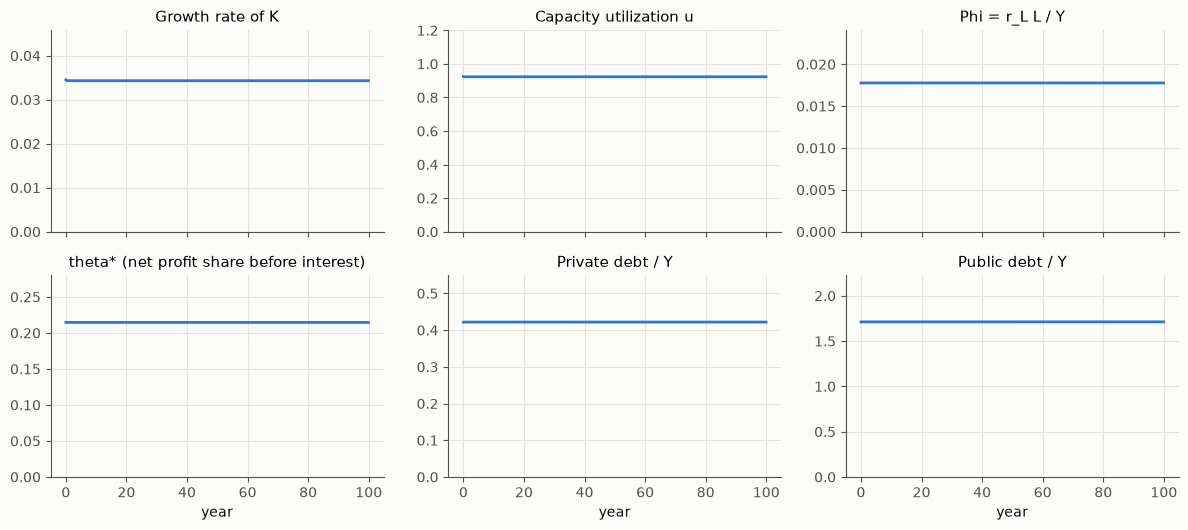

g=0.0343, u=0.923, Phi=0.0178, theta*=0.215, s_agg=0.116, rent_share=0.187, L/Y=0.422, B/Y=1.712


In [14]:
base = simulate_cm(T=100)
t = base['t']
fig, axes = plt.subplots(2, 3, figsize=(12, 5.4), sharex=True)
panels = [('g', 'Growth rate of K'), ('u', 'Capacity utilization u'), ('Phi', 'Phi = r_L L / Y'),
          ('theta_star', 'theta* (net profit share before interest)'), ('L_Y', 'Private debt / Y'),
          ('B_Y', 'Public debt / Y')]
for ax, (k, title) in zip(axes.flat, panels):
    ax.plot(t, base[k], color=PAL[0]); ax.set_title(title)
    lo, hi = base[k].min(), base[k].max()
    ax.set_ylim(min(0, lo * 1.2), hi * 1.3 + 1e-3)
for ax in axes[1]:
    ax.set_xlabel('year')
plt.tight_layout(); plt.show()
j = -1
print(f"g={base['g'][j]:.4f}, u={base['u'][j]:.3f}, Phi={base['Phi'][j]:.4f}, theta*={base['theta_star'][j]:.3f}, "
      f"s_agg={base['s_agg'][j]:.3f}, rent_share={base['rent_share'][j]:.3f}, L/Y={base['L_Y'][j]:.3f}, B/Y={base['B_Y'][j]:.3f}")

**図 7**: 改良モデルの基準経路。成長率 3.4%、稼働率 0.92 で、ぶれずに成長する。利払い負担率 Φ は約 0.02 で、利払い前の純利潤分配率 θ*(約 0.21)を大きく下回る。v5 と違い、**利子が所得として戻るので、Φ が 1 に向かって積み上がることはない。** 以下の実験では、この基準経路と、途中でショックを与えた経路との比(「基準比」)を見る。

## 8. 実験 1: 金利と準備率の非対称(金利の制度)

金利の制度で、20 年目から 1 年かけて (a) 政策金利を 3% から 6% へ上げる場合と、(b) 法定準備率を 5% から 20% へ上げる場合を比べる。どちらも貸出金利を上げる操作である。

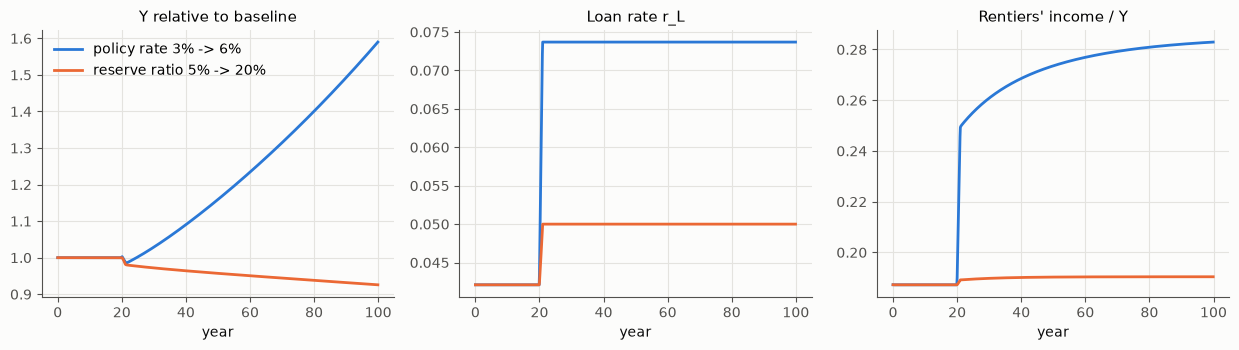

policy rate 3% -> 6%       Y/base: min 0.985, year 100 1.590; growth 0.0406 (base 0.0343)
reserve ratio 5% -> 20%    Y/base: min 0.926, year 100 0.926; growth 0.0337 (base 0.0343)


In [15]:
def run(**kw):
    return simulate_cm(T=100, **kw)


base = run()
cases = [('policy rate 3% -> 6%', dict(shocks=[(20, dict(r_cb=0.06), 1.0)])),
         ('reserve ratio 5% -> 20%', dict(shocks=[(20, dict(rho=0.20), 1.0)]))]
fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.6), sharex=True)
for k, (lab, kw) in enumerate(cases):
    h = run(**kw)
    axes[0].plot(t, h['Y'] / base['Y'], color=PAL[k], label=lab)
    axes[1].plot(t, h['r_L'], color=PAL[k], label=lab)
    axes[2].plot(t, h['rent_share'], color=PAL[k], label=lab)
axes[0].set(title='Y relative to baseline', xlabel='year')
axes[1].set(title='Loan rate r_L', xlabel='year')
axes[2].set(title="Rentiers' income / Y", xlabel='year')
axes[0].legend(); plt.tight_layout(); plt.show()
for lab, kw in cases:
    h = run(**kw)
    print(f"{lab:26s} Y/base: min {(h['Y'] / base['Y']).min():.3f}, year 100 {h['Y'][-1] / base['Y'][-1]:.3f};"
          f" growth {h['g'][-1]:.4f} (base {base['g'][-1]:.4f})")

**図 8**: 左は基準比の所得。準備率の引上げ(オレンジ)は、所得の水準を 7% ほど下げ、それが定着する。政策金利の引上げ(青)は、ほんの一瞬の落ち込みのあと、むしろ成長率を 3.4% から 4.1% に押し上げる。

理由は右の図にある。政策金利を上げると、国債の利子も預金の利子も上がり、**金利生活者の所得が増え、その一部が消費される。** 国債の残高が大きい経済では、この「利子所得の経路」が投資の減少を上回ることがある。これは、需要が所得を決めるタイプの成長モデルで以前から知られている現象で、「謎のケース(puzzling case)」と呼ばれてきた。ただし、利子が成長率を上回る水準(たとえば 8%)まで上げると、国債の利子が雪だるま式に増え、それが見かけの好況を作る(第 13 節)。一方、準備率の引上げは貸出金利だけを上げ、誰の所得も増やさない(準備は無利子)。だから純粋な引き締めになる。

「金利は誰かの所得になって経済に戻る」という出発点の直観は、ここではっきり効いてくる。v5 ではこれが落ちていたので、金利の引上げは常に引き締めに見えていた。ただし、この結果は**投資が株式的富にあまり反応しない場合**のものである。反応する場合は第 11・12 節で扱う。

## 9. 実験 2: タンス預金はいつ効くのか(量の制度と金利の制度)

20 年目から 1 年かけて、人々の現金選好 $cu_0$ を 0.05 から 0.30 に上げる(タンス預金化)。量の制度(ベースマネーを年 5% で伸ばす)と、金利の制度で比べる。量の制度では、同じ時期に準備率を 5% から 20% に上げる場合も並べる。

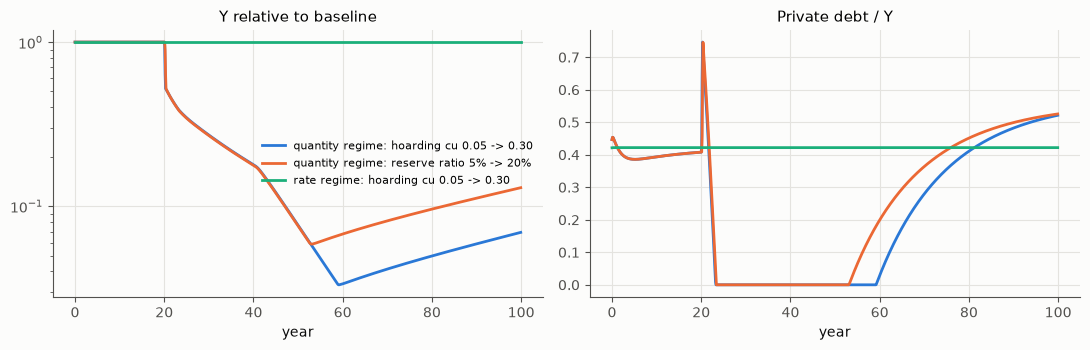

In [16]:
qbase = simulate_cm(T=100, regime='quantity', gH=0.05)
cases = [('quantity regime: hoarding cu 0.05 -> 0.30', 'quantity', dict(cu0=0.30)),
         ('quantity regime: reserve ratio 5% -> 20%', 'quantity', dict(rho=0.20)),
         ('rate regime: hoarding cu 0.05 -> 0.30', 'rate', dict(cu0=0.30))]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharex=True)
for k, (lab, reg, ch) in enumerate(cases):
    b = qbase if reg == 'quantity' else base
    h = simulate_cm(T=100, regime=reg, gH=0.05, shocks=[(20, ch, 1.0)])
    axes[0].plot(t, h['Y'] / b['Y'], color=PAL[k], label=lab)
    axes[1].plot(t, h['L_Y'], color=PAL[k], label=lab)
axes[0].set(title='Y relative to baseline', xlabel='year', yscale='log')
axes[1].set(title='Private debt / Y', xlabel='year')
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

**図 9**: 量の制度では、タンス預金化(青)も準備率の引上げ(オレンジ)も、信用の上限 $(1-\rho)H/(\rho+cu)$ を一気に下げる。企業は借入の返済を迫られ(右図で債務がほぼゼロまで落ちる)、投資が止まり、所得は基準の 1 割以下まで崩れる(左図は対数目盛)。大恐慌型の信用収縮である。このモデルの中央銀行は、ベースマネーを決まった率で伸ばし続けるだけで、危機に応じて増やしたりしない。そのため崩落は極端になり、回復には何十年もかかる。最後の貸し手として現金を出せば、ここまでは崩れない。

一方、金利の制度でのタンス預金化(緑の線)は、ほとんど何も起こさない。中央銀行が現金需要に応じて現金を出すからである。

まとめると、**v5 の「タンス預金化 = 実効準備率の上昇」は、量の制度ではそのまま正しく、しかも破壊力が大きい。金利の制度では効かない。** 現代の危機が「タンス預金」ではなく、資産価格と担保と銀行の損失から来るのはこのためである(第 11 節)。

## 10. 実験 3: 金利生活者の貯蓄と長期停滞

金利生活者の(所得からの)消費性向 $c_r$ を、20 年目から 1 年かけて 0.35 から 0.15 に下げる。富裕層がますます使わなくなる、という変化である。

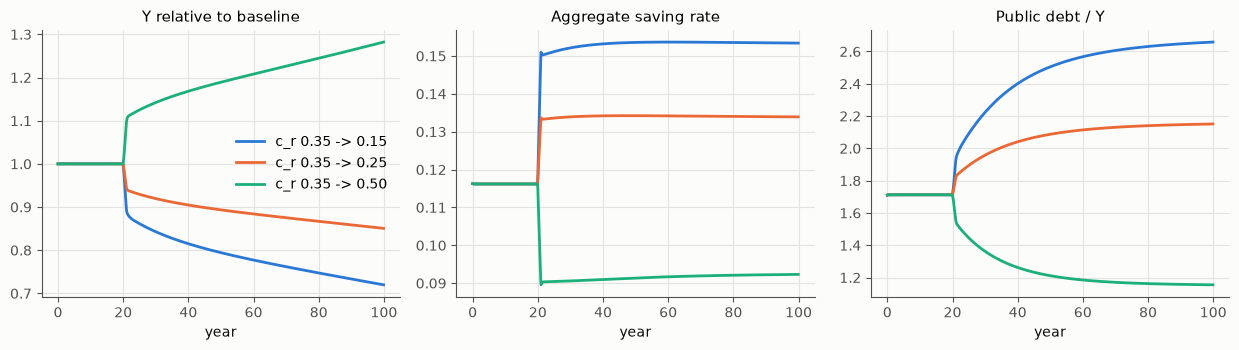

c_r 0.35 -> 0.15: Y/base at year 100 = 0.720; amount of saving / base: year 25 = 1.119, year 100 = 0.943


In [17]:
fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.6), sharex=True)
for k, cr in enumerate([0.15, 0.25, 0.50]):
    h = run(shocks=[(20, dict(c_r=cr), 1.0)])
    lab = f'c_r 0.35 -> {cr:.2f}'
    axes[0].plot(t, h['Y'] / base['Y'], color=PAL[k], label=lab)
    axes[1].plot(t, h['s_agg'], color=PAL[k], label=lab)
    axes[2].plot(t, h['B_Y'], color=PAL[k], label=lab)
axes[0].set(title='Y relative to baseline', xlabel='year')
axes[1].set(title='Aggregate saving rate', xlabel='year')
axes[2].set(title='Public debt / Y', xlabel='year')
axes[0].legend(); plt.tight_layout(); plt.show()
h = run(shocks=[(20, dict(c_r=0.15), 1.0)])
S, Sb = h['s_agg'] * (h['Y'] - h['tax']), base['s_agg'] * (base['Y'] - base['tax'])
print(f"c_r 0.35 -> 0.15: Y/base at year 100 = {h['Y'][-1] / base['Y'][-1]:.3f}; "
      f"amount of saving / base: year 25 = {S[250] / Sb[250]:.3f}, year 100 = {S[-1] / Sb[-1]:.3f}")

**図 10**: 金利生活者が使わなくなると(青・オレンジ)、所得は基準より低いままになり、差は年とともに広がる(長期停滞)。80 年後には、青の場合で基準の 7 割ほどになる。経済全体の貯蓄率は上がったまま高止まりする。ところが最後の出力のとおり、**貯蓄の額**は、最初は基準より 1 割ほど増えるものの、所得が減るにつれて 80 年後には基準を下回る。全員が貯蓄を増やそうとしても、所得が減るので貯蓄の額は増えない。これが「節約のパラドックス」である。

一方、政府債務の比率は上がり続ける。需要の不足を、政府の赤字が埋める形になるからだ。逆に金利生活者がよく使うようになれば(緑)、所得は上がり、政府債務の比率は下がる。

v5 の $s_{\rm eff}$ が表そうとした「分配が偏ると需要が細る」という効果は、閾値を置かなくても、**誰が所得を受け取るか**から自然に出てくる。

## 11. 実験 4: 株式的富のブームと崩壊、在庫維持能力

v5 で大事な役割を果たしていたのは、株式的富 $E$ と、その崩れが在庫の損耗を増やす経路(κ)だった。改良モデルでは、投資がトービンの $q=E/K$ にも反応するようにして($g_q=0.03$)、次のシナリオを比べる。

- **ブーム → 金利引上げ**: 10〜20 年目にかけて、株式のリスクプレミアムが 2% から 0.8% に下がる(「株式的富というペテンへの信頼」が高まる)。その後、25 年目から 1 年かけて政策金利を 3% から 6% に上げる。
- **同じシナリオで κ=0**: 崩れても在庫の損耗が増えない場合。
- **ブームなしで金利引上げ**: 比較用。

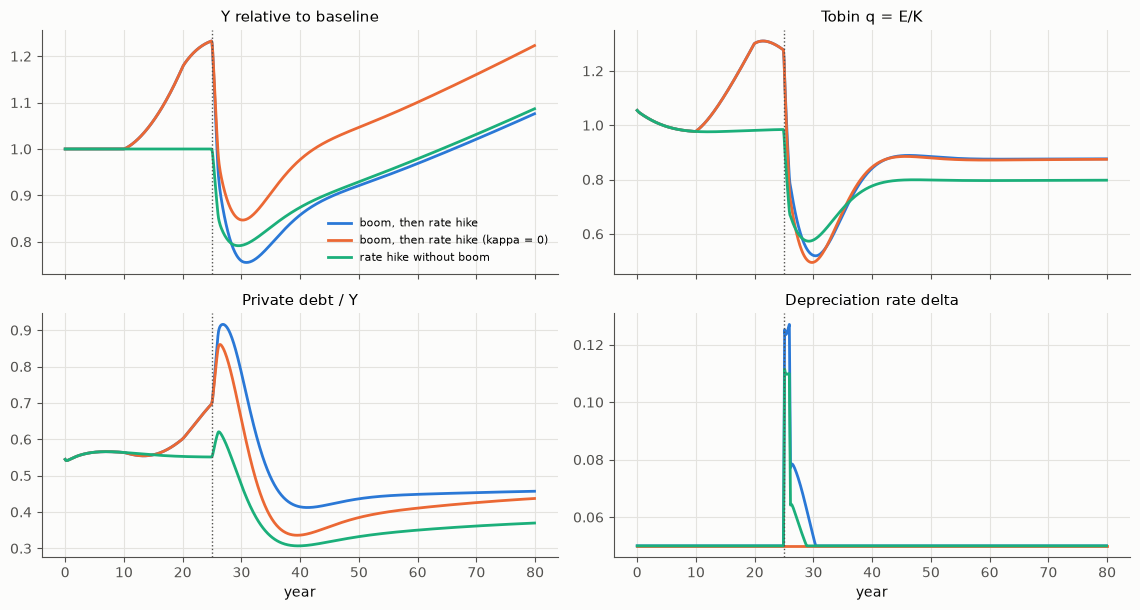

boom, then rate hike               peak 1.233  trough 0.755  fall 38.7%
boom, then rate hike (kappa = 0)   peak 1.233  trough 0.847  fall 31.3%
rate hike without boom             peak 1.000  trough 0.792  fall 20.8%


In [18]:
kwq = dict(g_q=0.03)
bq = simulate_cm(T=80, **kwq)
tq = bq['t']
euph = [(10, dict(prem=0.008), 10.0)]
hike = [(25, dict(r_cb=0.06), 1.0)]
scen = [('boom, then rate hike', dict(shocks=euph + hike)),
        ('boom, then rate hike (kappa = 0)', dict(kappa=0.0, shocks=euph + hike)),
        ('rate hike without boom', dict(shocks=hike))]
fig, axes = plt.subplots(2, 2, figsize=(11.5, 6.2), sharex=True)
res = {}
for k, (lab, kw) in enumerate(scen):
    h = simulate_cm(T=80, **kwq, **kw); res[lab] = h
    axes[0, 0].plot(tq, h['Y'] / bq['Y'], color=PAL[k], label=lab)
    axes[0, 1].plot(tq, h['q'], color=PAL[k], label=lab)
    axes[1, 0].plot(tq, h['L_Y'], color=PAL[k], label=lab)
    axes[1, 1].plot(tq, h['delta'], color=PAL[k], label=lab)
axes[0, 0].set_title('Y relative to baseline'); axes[0, 1].set_title('Tobin q = E/K')
axes[1, 0].set_title('Private debt / Y'); axes[1, 1].set_title('Depreciation rate delta')
for ax in axes[1]:
    ax.set_xlabel('year')
for ax in axes.flat:
    ax.axvline(25, color=INK2, lw=1, ls=':')
axes[0, 0].legend(fontsize=8); plt.tight_layout(); plt.show()
for lab, h in res.items():
    peak = (h['Y'] / bq['Y'])[:260].max(); trough = (h['Y'] / bq['Y'])[250:].min()
    print(f'{lab:34s} peak {peak:.3f}  trough {trough:.3f}  fall {1 - trough / peak:.1%}')

**図 11**: ブームの間(10〜25 年目)、株式的富 $q$ が上がり、投資と借入が増え、所得は基準を 2 割以上上回る。そこで金利を上げると(点線)、$E=\Pi^e/(r_L+\text{prem})$ の分母が上がって $q$ が急落する。投資が止まり、担保の価値が下がって借入の返済も迫られる。所得はピークから 4 割近く落ち、基準の水準に戻るまで 30 年以上かかる。

κ=0(オレンジ)では、落ち込みはピークから 3 割強にとどまる。右下の損耗率のとおり、崩れた瞬間に在庫(資本・知識・組織)が余分に失われることが、危機を深く長くしている。v5 にあった「**金融危機の最大の費用は、在庫を作る機会が失われることだ**」という見方は、このモデルでも確かめられる。

ブームなしの金利引上げ(緑)でも、投資が $q$ に反応する経済では 2 割ほどの落ち込みになる。第 8 節の「金利引上げがむしろ景気を押し上げる」結果とは逆である。違いは、投資が株式的富にどれだけ反応するかにある。これを次の節でまとめる。

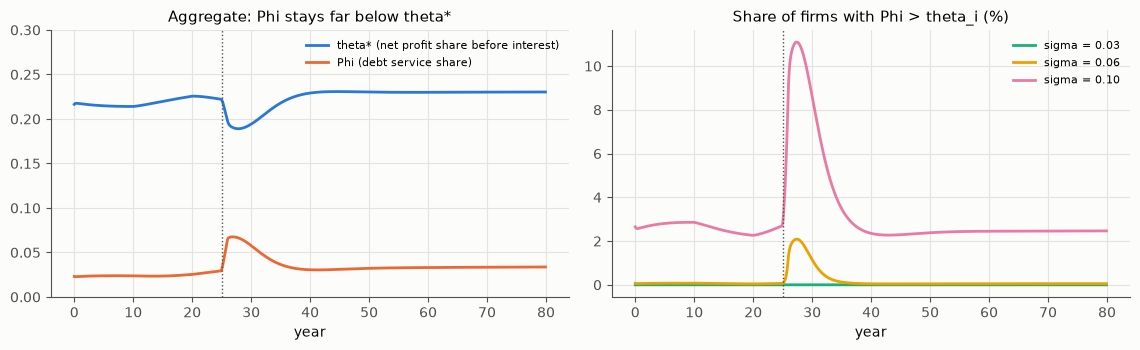

max Phi = 0.067, min theta* = 0.189
minsky classes seen (2=hedge, 1=speculative, 0=Ponzi): [np.int64(2)]


In [19]:
h = res['boom, then rate hike']
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.6), sharex=True)
axes[0].plot(tq, h['theta_star'], color=PAL[0], label='theta* (net profit share before interest)')
axes[0].plot(tq, h['Phi'], color=PAL[1], label='Phi (debt service share)')
axes[0].set(title='Aggregate: Phi stays far below theta*', xlabel='year', ylim=(0, 0.3))
axes[0].legend(fontsize=8)
for k, sig in enumerate([0.03, 0.06, 0.10]):
    # 企業ごとの閾値が N(theta*, sigma) に従うとき、利払い後に赤字になる企業の割合
    share = norm.cdf((h['Phi'] - h['theta_star']) / sig)
    axes[1].plot(tq, share * 100, color=PAL[k + 2], label=f'sigma = {sig:.2f}')
axes[1].set(title='Share of firms with Phi > theta_i (%)', xlabel='year')
for ax in axes:
    ax.axvline(25, color=INK2, lw=1, ls=':')
axes[1].legend(fontsize=8); plt.tight_layout(); plt.show()
print(f"max Phi = {h['Phi'].max():.3f}, min theta* = {h['theta_star'].min():.3f}")
print('minsky classes seen (2=hedge, 1=speculative, 0=Ponzi):', sorted(set(h['minsky'].astype(int))))

**図 12**: 同じシナリオ(ブーム → 金利引上げ)で、利払い負担 Φ と利払い前の純利潤分配率 θ* を並べた(左)。危機の最中でも Φ は最大 0.07 ほどで、θ*(最低でも 0.19)に遠く及ばない。**経済全体として「利払いが利潤を食い尽くす」ことは起きていない。** 企業の資金繰りを Minsky (1986) の 3 分類(ヘッジ・投機的・ポンジ)で数えても、集計値ではずっと「ヘッジ」のままである(最後の出力)。この危機は、利払い負担ではなく、**株式的富と担保の経路**から来ている。

ただし、企業ごとに θ_i がばらついていれば話は変わる(第 6.4 節)。右図は、θ_i が平均 θ*、標準偏差 σ の正規分布に従うとしたとき、$\Phi>\theta_i$ となる(利払い後に赤字になる)企業の割合である。σ が大きいほど、平時から赤字の企業が一定の割合で存在し、危機の直後にはその割合が跳ね上がる。**危機は「平均的な企業」ではなく「弱い企業」から始まる。** v5 の折れ線の閾値は、この分布の裾を一点に縮めたものと読める。

### 11.1 株式的富は在庫と結びついているか

ここで、v5 の土台にあった見方を検討しておく。「株式的富は、研究などを含む在庫の量と密接な関係を持つ」という見方である。v5 はこれを $E=K^\alpha/(r+\delta)$ と、式として固定していた。改良モデルでは $E=\Pi^e/(r_L+\text{prem})$ なので、$E$ と $K$ の関係は仮定ではなく結果になる。

**釣り合いの取れた成長経路の上では**、すべての量が同じ率で伸びるので、$E$ は $K$ に比例する。比例の係数がトービンの $q=E/K$ である。

$$
q^* \approx \frac{\Pi/K}{r_L+\text{prem}},\qquad \frac{\Pi}{K} = (1-\omega)\frac{u}{v} - \delta_0 - r_L\frac{L}{K}
$$

(実際には、期待利潤が成長に少し遅れて追いつくことと、分母の下駄の分だけ小さくなる。)つまり、**$E$ が $K$ に結びつくのは、資本が利潤を生むからである。** 係数 $q$ は、次の四つで動く。

- 分配: 賃金分配率 ω が上がると、$q$ は下がる。
- 需要: 稼働率 $u$ が下がる、つまり売れずに遊んでいる設備が増えると、$q$ は下がる。
- 負債: 借入の比率 $L/K$ が上がると、$q$ は下がる。
- 割引率: 貸出金利 $r_L$ やリスクプレミアムが上がると、$q$ は下がる。

v5 の式では、$q=K^{\alpha-1}/(r+\delta)$ は、在庫が増えるほど機械的に下がる。改良モデルでは、在庫の量そのものではなく、在庫が生む利潤が効く。

20 年目に、次の四つのショックを与えて、$E$ と $K$ が一緒に動くかどうかを見る。

- 賃金分配率を 0.65 → 0.70 に上げる(分配)。
- 金利生活者の消費性向を 0.35 → 0.15 に下げる(需要)。
- リスクプレミアムを 2% → 1% に下げる(ペテンへの信頼)。
- 政策金利を 3% → 6% に上げる(割引率)。

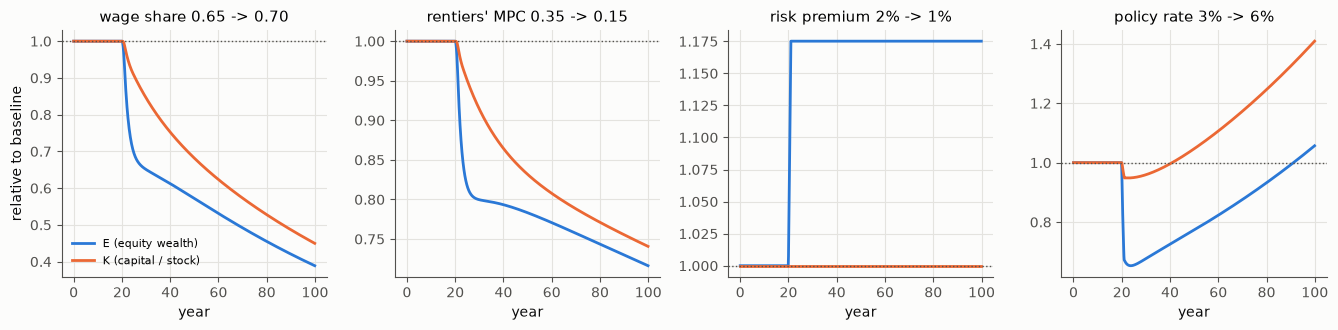

shock                          q(end)  u(end)  profit rate  K/base  E/base
baseline                        1.013   0.923      0.0727
wage share 0.65 -> 0.70         0.876   0.955      0.0619   0.450   0.389


rentiers' MPC 0.35 -> 0.15      0.980   0.897      0.0700   0.741   0.716
risk premium 2% -> 1%           1.191   0.923      0.0727   1.000   1.175


policy rate 3% -> 6%            0.760   1.041      0.0811   1.409   1.057


In [20]:
shocks4 = [('wage share 0.65 -> 0.70', dict(omega=0.70)), ("rentiers' MPC 0.35 -> 0.15", dict(c_r=0.15)),
           ('risk premium 2% -> 1%', dict(prem=0.01)), ('policy rate 3% -> 6%', dict(r_cb=0.06))]
fig, axes = plt.subplots(1, 4, figsize=(13.5, 3.4), sharex=True)
for ax, (lab, ch) in zip(axes, shocks4):
    h = simulate_cm(T=100, shocks=[(20, ch, 1.0)])
    ax.plot(t, h['E'] / base['E'], color=PAL[0], label='E (equity wealth)')
    ax.plot(t, h['K'] / base['K'], color=PAL[1], label='K (capital / stock)')
    ax.axhline(1, color=INK2, lw=1, ls=':')
    ax.set(title=lab, xlabel='year')
axes[0].set_ylabel('relative to baseline'); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()
print('shock                          q(end)  u(end)  profit rate  K/base  E/base')
print(f"{'baseline':30s} {base['q'][-1]:6.3f} {base['u'][-1]:7.3f} {base['Pi'][-1] / base['K'][-1]:11.4f}")
for lab, ch in shocks4:
    h = simulate_cm(T=100, shocks=[(20, ch, 1.0)])
    print(f"{lab:30s} {h['q'][-1]:6.3f} {h['u'][-1]:7.3f} {h['Pi'][-1] / h['K'][-1]:11.4f} "
          f"{h['K'][-1] / base['K'][-1]:7.3f} {h['E'][-1] / base['E'][-1]:7.3f}")

**図 12b**: 青が株式的富 $E$、オレンジが在庫・資本 $K$ で、どちらも基準経路との比。

- **分配と需要のショック**(左の二つ)では、まず利潤が落ちて $E$ が先に下がり、投資が細って $K$ が後から追いかける。その後は、二つは同じ向きに離れていく。どちらのショックも、利潤 → 投資 → 資本の蓄積という同じ経路を通るからである。賃金分配率が上がると利潤率が下がり、成長が鈍って、80 年後には $E$ も $K$ も基準の半分以下になる(このモデルの投資は利潤に強く反応する「利潤主導」型である)。
- **リスクプレミアムの低下**では、$E$ だけが 2 割近く上がり、$K$ はまったく変わらない(この設定では投資が $q$ に反応しないので)。株式的富は、在庫が増えなくても膨らむ。
- **金利の引上げ**では、割引率が上がって $E$ が一気に 3 割以上下がる。一方、利子所得の経路で需要が増えるので、$K$ はむしろ速く積み上がる。その結果、$q$ は 0.76 まで下がり、$E$ と $K$ の差は開いたままになる。

まとめると、「株式的富は在庫と密接な関係を持つ」は**半分だけ正しい**。

- **正しい点**: 平時の長い目で見れば、$E\approx q\cdot K$ で、$q$ は 1 前後に落ち着く。実証でも、株式の時価総額は、帳簿に載らない研究・ソフトウェア・組織などの**無形資産**の大きさを映していると考えられている。Hall (2001) は株式の時価から無形資本の蓄積を推計した。Corrado, Hulten and Sichel (2009) は、米国の公式統計から漏れている無形資本が 3 兆ドルを超えると見積もった。Peters and Taylor (2017) は、無形資本を含めるとトービンの q が投資をよく説明することを示した。「研究も在庫に含めて考える」という見方は、この意味で筋がよい。
- **正しくない点**: $E$ と $K$ をつないでいるのは在庫の量ではなく、**在庫が生む利潤と、それを割り引く率**である。分配、需要、負債、金利、リスクプレミアムのどれかが動けば、$q$ は動く。リスクプレミアムや金利が動けば、$E$ と $K$ は離れる。売れ残りの在庫は利潤を生まないので、増えれば $u$ を下げ、むしろ $q$ を下げる。

だから、$E$ を $K$ の関数として固定する v5 の式より、$E$ を利潤の資本還元として独立に動かし、投資が $q$ を通じて $K$ に返る、とする方が現実に近い。この「株式的富の独立性」があるからこそ、第 11 節のブームと崩壊が起きる。

## 12. 金利の三つの経路

ここまでの実験から、金利が所得に効く経路は少なくとも三つあることがわかった。

1. **利子所得の経路(+)**: 利子は金利生活者の所得になり、一部が消費される。国債や預金の残高が大きいほど強い。
2. **株式的富・担保の経路(−)**: 金利が上がると $E$ が縮み、投資と借入が減る。投資が $q$ に敏感なほど強い。
3. **利払い負担の経路(−)**: Φ が θ* に近づくと、企業の損失と貸倒れが出る。負債が厚いほど強い。

経路 1 と 2 の綱引きを、地図にして見る。縦軸に投資の $q$ への反応 $g_q$、横軸に政府支出の大きさ(政府支出が小さいほど成長が遅く、国債の残高比率が大きくなる)をとる。色は「25 年目に金利を 3% から 6% へ上げてから 10 年後の所得の、基準との比」である。

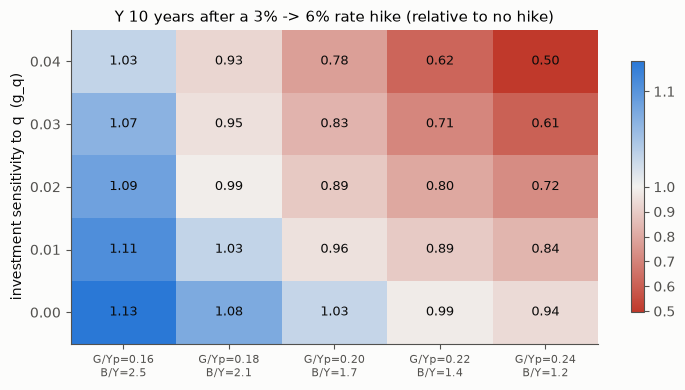

In [21]:
gqs = [0.0, 0.01, 0.02, 0.03, 0.04]
gGs = [0.16, 0.18, 0.20, 0.22, 0.24]
Z = np.zeros((len(gqs), len(gGs))); BY = np.zeros(len(gGs))
for i, gq in enumerate(gqs):
    for j, gG in enumerate(gGs):
        b = simulate_cm(T=40, g_q=gq, gG=gG)
        h = simulate_cm(T=40, g_q=gq, gG=gG, shocks=[(25, dict(r_cb=0.06), 1.0)])
        Z[i, j] = h['Y'][350] / b['Y'][350]
        if i == 0:
            BY[j] = b['B_Y'][0]
fig, ax = plt.subplots(figsize=(7.5, 4))
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
cmap = LinearSegmentedColormap.from_list('div', ['#c0392b', '#f2f1ee', '#2a78d6'])
im = ax.imshow(Z, cmap=cmap, norm=TwoSlopeNorm(1.0, vmin=Z.min(), vmax=max(Z.max(), 1.01)),
               origin='lower', aspect='auto')
for i in range(len(gqs)):
    for j in range(len(gGs)):
        ax.text(j, i, f'{Z[i, j]:.2f}', ha='center', va='center', fontsize=9, color=INK)
ax.set_xticks(range(len(gGs)), [f'G/Yp={g:.2f}\nB/Y={b:.1f}' for g, b in zip(gGs, BY)], fontsize=8)
ax.set_yticks(range(len(gqs)), [f'{g:.2f}' for g in gqs])
ax.set(ylabel='investment sensitivity to q  (g_q)', title='Y 10 years after a 3% -> 6% rate hike (relative to no hike)')
ax.grid(False); plt.colorbar(im, ax=ax, shrink=0.8); plt.tight_layout(); plt.show()

**図 13**: 青(1 より大)は「金利引上げで所得が増えた」、赤(1 より小)は「減った」を表す。左下ほど(国債残高が大きく、投資が $q$ に鈍い)利子所得の経路が勝ち、右上ほど(国債残高が小さく、投資が $q$ に敏感)株式的富の経路が勝つ。

ここから言えるのは次のことである。

- **金利が「効く」かどうか、どちらの向きに効くかは、経済の構造で決まる。** 金利だけを見て信用創造の限界を語ることはできない。
- この結果は、出発点の直観をある意味で裏付ける。「金利は分配を規定するが、信用の量そのものを律するわけではない」。
- ただし直観と違う点もある。準備率が信用の量を律するのは、量の制度のときだけである(第 9 節)。

## 13. 国家を入れる

### 13.1 国家を「パラメータの調整」として入れるか、「部門」として入れるか

v5 には国家が出てこない。v5 に国家をどう入れるかについては、いくつかの案が出ていた。整理すると次のようになる。

| 案 | 国家の効き方 |
|---|---|
| 実効金利の加重平均 | 国家の規模 $G/Y$ に応じて、民間金利 $r$ と国家の金利 $r_{\rm state}$ を混ぜる。さらに、ある規模を超えると $\alpha$(在庫→株式的富の変換効率)と $\lambda$(株式的富→信用)を下げる |
| α を国家能力で上げる | $\alpha=\alpha_0+\eta G$。上げすぎると第 4 節のとおり脆くなるので、「ある程度までは株式的富を増やすが、その先は逆効果」になる |
| δ_C を下げる | 教育・医療・治安・物流が、消費側の損耗を減らす(古典的な公共財論) |
| γ を上げる | 国家が肥大化すると、規制や既得権保護で実効の貯蓄性向が上がり、消費が細る |
| α を山形に | $\alpha(G)=\alpha_0+\Delta\alpha\,G(1-G/G_{\max})$。税は可処分所得を削る強制貯蓄として $s_{\rm eff}$ に足す |

どの案も、**既にあるパラメータを国家の大きさで動かす**ものだった。そこから「v5 はそのままにして、国家はパラメータを外から注入して分析すれば足りる」という考え方も出てくる。

この文書の立場は少し違う。**国家は、自分の貸借対照表を持つ一つの部門として入れるべきだ**と考える。国家は次の三つを同時に行う。

- 支出 $G$ で需要を作る。
- 税で所得を取る。
- 国債 $B$ を出し、その利子を国債の保有者の所得にする。

最後の点が特に大事である。国債の利子は「誰かの所得として戻ってくる利子」そのものであり、第 4 節で見た v5 の弱点と、第 8 節の「金利引上げの利子所得経路」に直結している。パラメータの調整では、この帳尻が表せない。

ただし、これは「国家は信用の世界経済に埋め込めない」という意味ではない。**会計の面では、国家も企業と同じく貸借を持つ一つの単位である。** だから、パラメータとしてではなく部門として埋め込めば、企業を連結決算でまとめるのと同じように、複数の国家を連結して一つの国家のように扱える(13.3 節)。国家が企業と違うのは、税を取ること、国債の利子が誰かの所得になること、そして金利の制度か量の制度かといった「制度」の境界を決めることである。

### 13.2 国債比率の動き方: r と g(ドーマー条件)

国債の残高比率 $b=B/Y$ は、プライマリー赤字の比率を $d$($=(G-\text{税})/Y$)として

$$
\frac{db}{dt} = d + (r-g)\,b
$$

で動く。$r<g$(金利が成長率より低い)なら、$b$ は $b^*=d/(g-r)$ に収束する。$r>g$ なら、プライマリー収支が十分な黒字でない限り、$b$ は発散する(Domar 1944)。「インフレ率(成長率)より国債の金利が低ければ問題ない」という直観の正確な形がこれである。

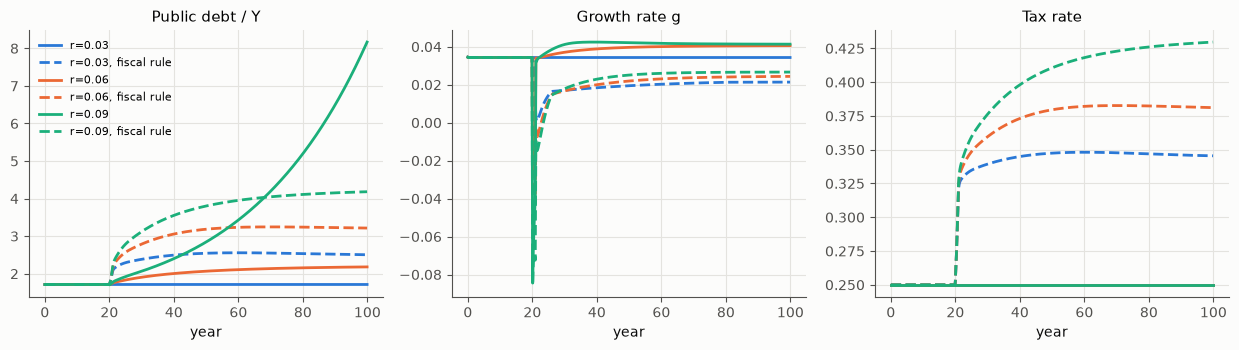

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.6), sharex=True)
for k, r in enumerate([0.03, 0.06, 0.09]):
    for ls, fr in [('-', 0.0), ('--', 0.05)]:
        h = simulate_cm(T=100, shocks=[(20, dict(r_cb=r, fiscal=fr), 1.0)])
        lab = f'r={r:.2f}' + (', fiscal rule' if fr else '')
        axes[0].plot(t, h['B_Y'], color=PAL[k], ls=ls, label=lab)
        axes[1].plot(t, h['g'], color=PAL[k], ls=ls, label=lab)
        axes[2].plot(t, h['tau'], color=PAL[k], ls=ls, label=lab)
axes[0].set(title='Public debt / Y', xlabel='year')
axes[1].set(title='Growth rate g', xlabel='year')
axes[2].set(title='Tax rate', xlabel='year')
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

**図 14**: 20 年目に、政策金利を 3%・6%・9% に変える(実線: 税率は固定)。3% と 6% では国債比率は落ち着く。6% は成長率(約 4.1%)より高いが、利子にも税がかかるので、税引き後の利子率で見れば成長率とほぼ釣り合う。9% では利子の伸びが成長を上回り、国債比率は上がり続ける。

破線は、同時に「国債比率が 0.6 を超えた分に応じて税率を上げる」財政ルールを入れた場合。9% の場合は上昇が抑えられる。ところがどの金利でも、**ルールを入れた方が、ルールなしの 3%・6% の場合より国債比率が高い水準に落ち着き、成長率は 2%台に下がる。** 税を上げると需要が減って成長率が下がり、分母の $Y$ が伸びなくなるからである。需要で所得が決まる経済では、財政再建を急ぐと、成長の鈍化を通じて債務比率を押し上げることがある。

### 13.3 二国のモデルを一国に「縮約」するには何が要るか

v5 は国家を持たない、いわば「世界経済」のモデルだった。それなら、国の間でお金と資本が行き来する二国のモデルを、一国のモデルに縮約できないか。縮約に足りない「パラメータ」こそが、v5 に足すべき要素ではないか。そういう問いがあった。

改良モデルで考えると、縮約に要る最小の部品の一つがはっきりする。**利子・配当のうち、国外の債権者に渡る割合**である。国外に渡った利子は、国内では消費も課税もされない。つまり国内から見ると、**利子が経済から消える**。下の図は、その割合を 0, 25%, 50% にしたものである。

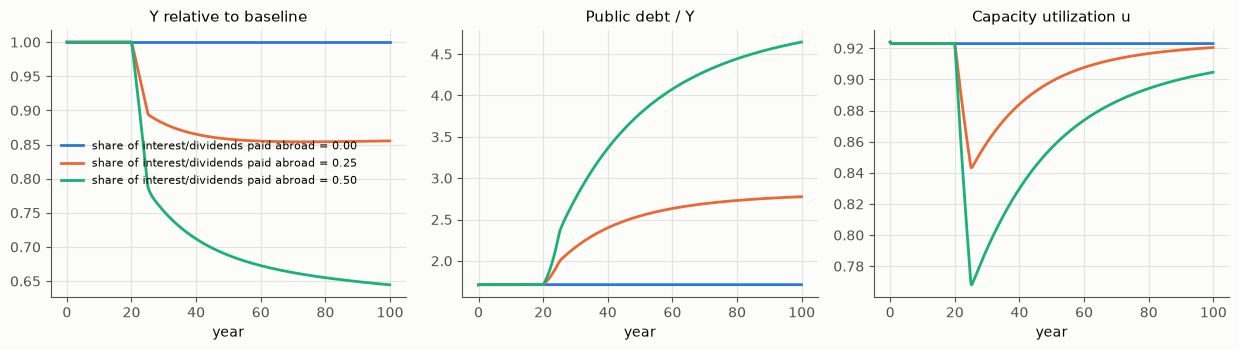

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.6), sharex=True)
for k, f in enumerate([0.0, 0.25, 0.5]):
    h = simulate_cm(T=100, shocks=[(20, dict(foreign=f), 5.0)])
    lab = f'share of interest/dividends paid abroad = {f:.2f}'
    axes[0].plot(t, h['Y'] / base['Y'], color=PAL[k], label=lab)
    axes[1].plot(t, h['B_Y'], color=PAL[k], label=lab)
    axes[2].plot(t, h['u'], color=PAL[k], label=lab)
axes[0].set(title='Y relative to baseline', xlabel='year')
axes[1].set(title='Public debt / Y', xlabel='year')
axes[2].set(title='Capacity utilization u', xlabel='year')
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

**図 15**: 利子・配当の国外流出が増えると、国内の需要が細り(稼働率が下がる)、税収も減る。その結果、国債比率が上がり続ける。流出の割合を 100% にすると、改良モデルは「利子が経済から消える」v5 と同じ構造になる。**v5 は、利子をすべて国外の債権者に払う一国経済のモデルとも読める。**

逆に言えば、v5 を「世界経済」として読むなら、利子は世界のどこかで誰かの所得になっているはずで、それを戻さなければ世界全体の帳尻が合わない。

では、大きさの違う二国のモデル $M_B$, $M_C$ をつないだ経済を、一国のモデル $M_A$ として描けるか。どこまで厳密に言えるかは、三つの層で違う。

1. **会計(貸借と取引の流れ)**: **厳密に**連結できる。連結とは、国の間の取引を相殺して合計することである。この操作は、結合的で可換で、単位元(空の経済)を持つ。
2. **線形の行動式**(消費性向など): 一時点で見る限り、**厳密に**集計できる。$M_A$ のパラメータは、$M_B$, $M_C$ のパラメータを規模(流れの大きさ)で重み付けた平均になる。加重平均も結合的である。
3. **動学と非線形**: **近似**になる。足りないものは次の三つである。これが「縮約に足りないパラメータ」の正体である。
   - **構成比**: 国ごとの成長率が違えば、二国の比重が動く。だから $M_A$ のパラメータも時間とともに動く。
   - **閾値の分布**: $\max(0,\Phi-\theta)$ のような折れ線は、平均の国に当てはめても、合計とは一致しない(第 6.4 節と同じ理由)。パラメータを「数」ではなく「分布」として持てば、連結は分布の混合になり、連結について閉じる。
   - **国の間の流れ**: 輸入性向(需要の国外への漏れ)、輸出(国外からの需要)、資本の移動、そして上の図の部品である利子・配当の国境を越える受け払い。

改良モデルで試すと、次のようになる。ここでは、国の間に貿易や資金のやりとりがない場合だけを調べた。

- パラメータが同じ二国の合計は、大きな一国と一致する。モデルが規模について同次だからである。
- 金利生活者の消費性向だけが違う二国(0.25 と 0.6、規模は 7:3)を比べる。加重平均の消費性向を持つ一国は、成長率 3.43% で一定のまま進む。二国の合計の成長率は、成長の速い国の比重が増えるにつれて 3.44% から 3.47% へ上がっていく。
- 金利引上げへの反応(株式的富への投資の感応度が違う二国)では、落ち込みの深さは二国の合計と一国でほぼ同じになる(底は 0.85 と 0.87)。回復の速さは食い違う。

**定性的な議論は一致し、定量的には構成比と分布の分だけずれる**、というのが今の見通しである。逆向きに、$M_A$ の変化を $M_B$, $M_C$ に「射影」することもできる。ただし、集計は多対一なので、射影は配分の規則(規模に比例する、など)を選んだときにだけ一つに決まる。この連結と縮約の理論は、多国版のモデルと Lean による証明を含めて、続編のノート「[信用の世界経済は一つか](https://github.com/JRF-2018/credit_simulation_v6/blob/master/notebooks/credit_linkage.ipynb)」で扱った。

## 14. 労働を入れる

### 14.1 労働を「読み出し」にするだけでは閉じない

労働の入れ方として、次のような考え方があった。

- 労働 = (雇用率 ζ)×(人口)、必需品の生産能力 = (一人あたりの能力)×(労働)。
- 金融拡張 → 所得の増加 → 必要な労働の増加 → 雇用率の変化、と読み出す(逆に、雇用の目標から必要な金融拡張を逆算する)。
- 労働はモデル本体に入れず、外付けの読み出し層にするのが自然である。

この案を改良モデルで試す。雇用率を $e=Y/(a\cdot\text{Pop})$ とする($a$ は労働生産性で年 1.5% 伸び、人口は年 0.5% 伸びる)。雇用率はモデルの結果を読み出すだけで、モデルには何も返さない。

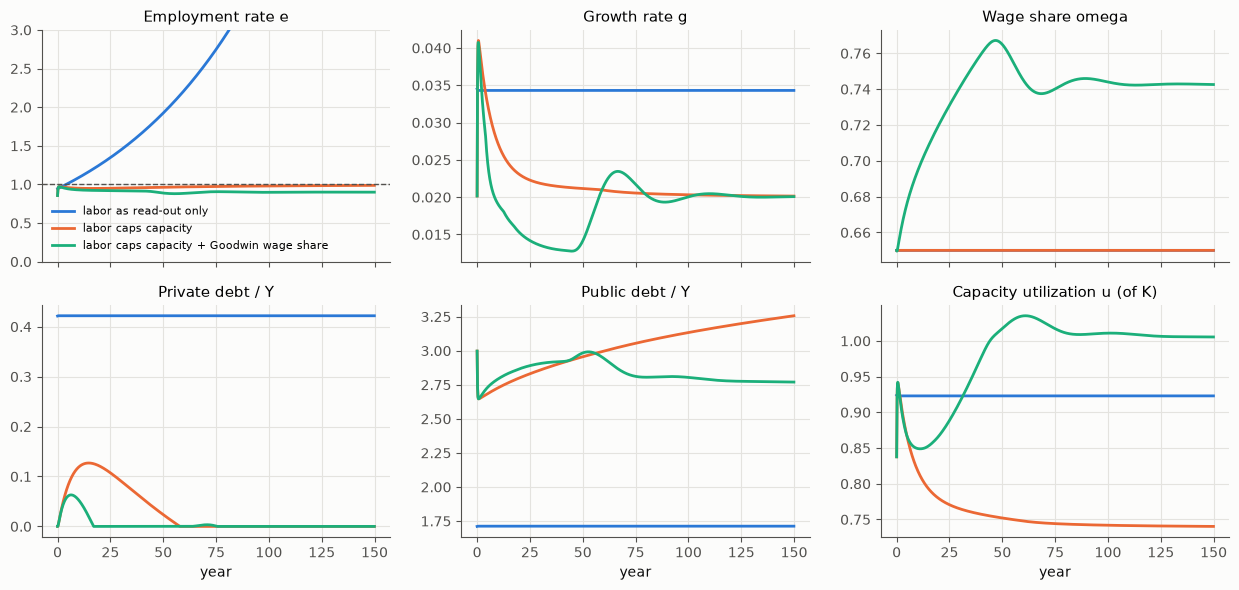

read-out     e=7.989 g=0.0343 omega=0.650 L/Y=0.422 B/Y=1.71
cap          e=0.988 g=0.0201 omega=0.650 L/Y=0.000 B/Y=3.26
cap+Goodwin  e=0.900 g=0.0201 omega=0.743 L/Y=0.000 B/Y=2.77


In [24]:
ro = simulate_cm(T=150)
lc = simulate_cm(T=150, labor_cap=True)
gw = simulate_cm(T=150, labor_cap=True, phillips=0.15)
t150 = ro['t']
fig, axes = plt.subplots(2, 3, figsize=(12.5, 6), sharex=True)
for k, (lab, h) in enumerate([('labor as read-out only', ro), ('labor caps capacity', lc),
                              ('labor caps capacity + Goodwin wage share', gw)]):
    axes[0, 0].plot(t150, h['emp'], color=PAL[k], label=lab)
    axes[0, 1].plot(t150, h['g'], color=PAL[k], label=lab)
    axes[0, 2].plot(t150, h['omega'], color=PAL[k], label=lab)
    axes[1, 0].plot(t150, h['L_Y'], color=PAL[k], label=lab)
    axes[1, 1].plot(t150, h['B_Y'], color=PAL[k], label=lab)
    axes[1, 2].plot(t150, h['u'], color=PAL[k], label=lab)
axes[0, 0].axhline(1, color=INK2, lw=1, ls='--')
axes[0, 0].set(title='Employment rate e', ylim=(0, 3)); axes[0, 1].set_title('Growth rate g')
axes[0, 2].set_title('Wage share omega'); axes[1, 0].set_title('Private debt / Y')
axes[1, 1].set_title('Public debt / Y'); axes[1, 2].set_title('Capacity utilization u (of K)')
for ax in axes[1]:
    ax.set_xlabel('year')
axes[0, 0].legend(fontsize=8); plt.tight_layout(); plt.show()
for lab, h in [('read-out', ro), ('cap', lc), ('cap+Goodwin', gw)]:
    print(f"{lab:12s} e={h['emp'][-1]:.3f} g={h['g'][-1]:.4f} omega={h['omega'][-1]:.3f} L/Y={h['L_Y'][-1]:.3f} B/Y={h['B_Y'][-1]:.2f}")

**図 16**: 青(読み出しだけ)では、雇用率が 1(破線)を超えて伸び続ける。改良モデルの成長率 3.4% が、労働の伸び(生産性 1.5% + 人口 0.5% = 2%)を上回っているからである。**読み出しだけの労働は、金融側が自然成長率と違う速さで成長する限り、すぐに矛盾する。** 外付けにしてよいのは短い期間の読み出しだけで、長期には労働はモデルに何かを返さなければならない。

(どの線も最初の数年に跳ねているのは、初期値を「労働の天井がない経路」から取っているための調整で、意味のある動きではない。)

返し方を二つ試した。

**(a) 労働が生産能力の天井になる**(オレンジ): 生産能力を「資本で決まる能力」と「完全雇用で決まる能力」の小さい方にする(なめらかな min)。成長率は自然成長率の 2% に収束する。資本は余り、稼働率が下がる。利潤で投資が賄えるので企業は借金を返し、民間債務は消える。代わりに政府の債務比率が上がる。**企業は借りず、国が借りる。** どこかで見た姿ではないだろうか。

**(b) さらに賃金分配率が雇用率で動く**(緑、Goodwin 1967): 雇用率が目標(0.90)を上回ると賃金分配率が上がり、下回ると下がる。賃金分配率は 0.65 から 0.75 近くまで上がる。利潤が圧縮されて投資が減り、雇用率が 0.90 に落ち着く所で釣り合う。**分配(賃金分配率)は労働市場で決まり、その分配が θ*(利払い前の純利潤分配率)を動かし、ひいては信用の限界を動かす。** これが、労働を外付けにできない一番の理由である。

### 14.2 許容価格と生産能力: 需要が能力を超えた分はどこへ行くか

需要と供給については、所得を「許容価格 $P$ × 生産能力 $PA$」に、実現の度合い $\omega$ をかけたもの($Y=\omega(P_L PA_L+P_N PA_N)$)として書く案があった。改良モデルの言葉に直すと、次のようになる。

- 生産能力 $PA$: 資本と労働で決まる能力 $Y_p$。
- 需要: 支出の合計 $Y^d$。
- 実現した所得: $Y=\min(Y^d, Y_p)$ のなめらかな版。

このモデルには物価がないので、能力を超えた需要 $Y^d-Y$ は実現しない。現実には、その分が**価格の上昇圧力**(許容価格の上昇)になるはずだ。労働の天井があるとき、政府支出を大きくすると何が起きるかを見る。

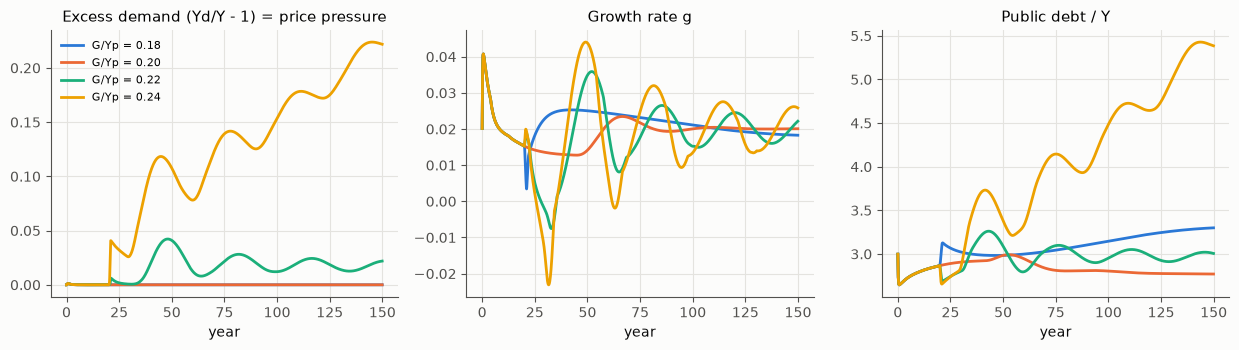

G/Yp=0.18: excess demand 0.000, g 0.0183, B/Y 3.30, wage share 0.642


G/Yp=0.20: excess demand 0.000, g 0.0201, B/Y 2.77, wage share 0.743


G/Yp=0.22: excess demand 0.022, g 0.0222, B/Y 3.01, wage share 0.757


G/Yp=0.24: excess demand 0.222, g 0.0258, B/Y 5.39, wage share 0.746


In [25]:
fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.6), sharex=True)
for k, gG in enumerate([0.18, 0.20, 0.22, 0.24]):
    h = simulate_cm(T=150, labor_cap=True, phillips=0.15, shocks=[(20, dict(gG=gG), 1.0)])
    lab = f'G/Yp = {gG:.2f}'
    axes[0].plot(t150, h['Yd'] / h['Y'] - 1, color=PAL[k], label=lab)
    axes[1].plot(t150, h['g'], color=PAL[k], label=lab)
    axes[2].plot(t150, h['B_Y'], color=PAL[k], label=lab)
axes[0].set(title='Excess demand (Yd/Y - 1) = price pressure', xlabel='year')
axes[1].set(title='Growth rate g', xlabel='year')
axes[2].set(title='Public debt / Y', xlabel='year')
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()
for gG in [0.18, 0.20, 0.22, 0.24]:
    h = simulate_cm(T=150, labor_cap=True, phillips=0.15, shocks=[(20, dict(gG=gG), 1.0)])
    print(f"G/Yp={gG:.2f}: excess demand {h['Yd'][-1] / h['Y'][-1] - 1:.3f}, g {h['g'][-1]:.4f}, "
          f"B/Y {h['B_Y'][-1]:.2f}, wage share {h['omega'][-1]:.3f}")

**図 17**: 労働の天井があり、賃金分配率が雇用率で動く経済で、20 年目に政府支出の比率を 0.20 から 0.18〜0.24 に変えた。0.18〜0.22 では、成長率はどれも自然成長率 2% 前後に戻り、超過需要もほとんど出ない(0.22 以上では、賃金分配率と雇用率が追いかけ合う「グッドウィン循環」が出て、成長率が波打つ)。**政府の大きさは長期の成長率ではなく、分配(賃金分配率)と債務比率を変える。** 0.24 まで上げると、需要が完全雇用の能力を超え、超過需要(価格圧力)が 2 割ほど出続ける。このモデルには物価がないので、超過需要は実現しない。税収は伸びないのに支出は続くので、国債比率は 5 を超えて上がる。

現実なら、この超過需要は物価の上昇になる。名目の所得が伸び、実質の国債残高を目減りさせる(インフレによる債務の希釈)。**労働の天井と物価をどう入れるかは、次に取り組むべき課題である**(第 16 節)。

## 15. 持続可能な信用拡張の条件: r と g

最後に、「信用拡張が続けられるのは、借入が将来の所得を生み、その所得の増加が利払い・元本返済を吸収できる範囲に限られる。その限界を越えた部分は、金融的には維持できても、実体経済の裏付けを失う」という命題を式にする。

民間債務の比率 $l=L/Y$ は、所得の成長率を $g$、新規の借入の(所得に対する)比率を $x$ とすると、

$$
\frac{dl}{dt} = x - g\,l .
$$

**ヘッジ型**(投資のために借り、利払いは営業利益で払う)なら、$x$ は投資の一部で上限があり、$l$ は $l^*=x/g$ に落ち着く。利払い負担は $\Phi^*=r\,x/g$ になる。**成長が借入を「吸収」している。**

**ポンジ型**(利払いをまた借りて払う)なら、$x$ に $r\,l$ が加わって

$$
\frac{dl}{dt} = x + (r-g)\,l
$$

となる。$r<g$ ならそれでも $l^*=x/(g-r)$ に落ち着くが、$r>g$ なら発散する。命題の正確な形は「**利払いを借入で払う部分があるなら、金利が成長率を超えた時点で、その信用拡張は実体の裏付けを失う**」である。国債についての第 13.2 節の条件と同じ形をしている。

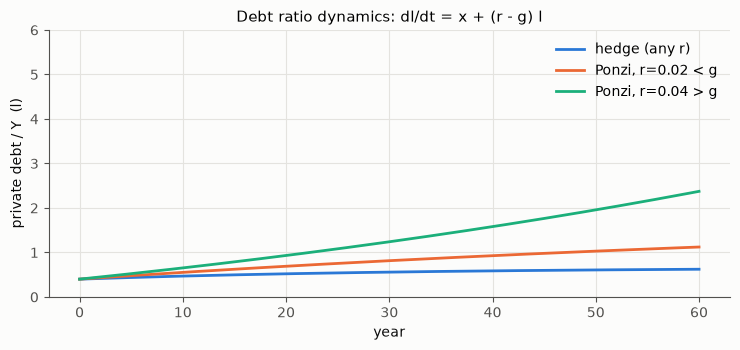

In [26]:
tt = np.linspace(0, 60, 601)
x, g = 0.02, 0.03
fig, ax = plt.subplots(figsize=(7.5, 3.6))
specs = [('hedge (any r)', lambda r: x / g + (0.4 - x / g) * np.exp(-g * tt), 0.0),
         ('Ponzi, r=0.02 < g', None, 0.02), ('Ponzi, r=0.04 > g', None, 0.04)]
for k, (lab, f, r) in enumerate(specs):
    if f is not None:
        y = f(r)
    else:
        a = r - g
        y = (0.4 + x / a) * np.exp(a * tt) - x / a
    ax.plot(tt, y, color=PAL[k], label=lab)
ax.set(xlabel='year', ylabel='private debt / Y  (l)', title='Debt ratio dynamics: dl/dt = x + (r - g) l', ylim=(0, 6))
ax.legend(); plt.tight_layout(); plt.show()

**図 18**: 成長率 3%、新規借入の比率 2%、初期の債務比率 0.4 の場合。ヘッジ型(青)は $l^*=0.67$ に、$r<g$ のポンジ型(オレンジ)は $l^*=2$ に落ち着く。$r>g$ のポンジ型(緑)は発散する。v5 では、利払いが経済から消える一方で、新しい信用の流れ $C_{\rm flow}$ が利払い $rC$ を埋めていた。定常状態では「新しい信用がすべて利払いに吸われる」ので、v5 の定常状態は、いわば恒常的なポンジ状態だったことになる。

## 16. まとめ: v5 が正しかったこと、直すべきこと、残る問い

### v5 が正しかったこと

- **株式的富 $E$ を、金利で割り引いた将来の価値として扱い、それが信用の担保になる**という構造。改良モデルでも、ブームと崩壊の主役はこれだった(第 11 節)。これは Kiyotaki and Moore (1997) の「信用サイクル」や、Minsky の金融不安定性仮説と同じ系統の発想である。
- **崩れるときに在庫の損耗が増える**($\kappa$)。危機の深さと長さを大きく左右した。
- **タンス預金化が実効準備率を上げる**($\rho_{\rm eff}=\rho+cu$)。量の制度では正確で、しかも破壊的である(第 9 節)。
- **利払い負担 Φ が、ある水準を超えると危機が非線形に効く**という形。閾値 θ は「利払い前の純利潤分配率 θ*」と読めば意味を持つ(第 6 節)。

### 直すべきこと

1. **利子が経済から消える。** これが v5 の最大の弱点で、定常状態の $\Phi^*\ge1$ と、どの金利でも必ず起きる崩壊の原因だった(第 4 節)。v5 の「安定成長」と「臨界金利」は、150 期という観察の窓が作ったものだった。
2. **所得が信用の流れだけで決まり、貯蓄がそのまま在庫になる。** 需要(誰が使うか)と投資(誰が決めるか)を分けないと、分配が需要に与える効果が閾値の形でしか入らない。
3. **在庫 $K$ に、生産能力と売れ残りが混ざっている。** 売れ残りの在庫が増えるのは需要不足の症状で、生産能力の蓄積とは逆の意味を持つ。
4. **銀行の制度が一つしかない。** 量の制度と金利の制度では、ρ も cu もまったく違う効き方をする。

### 出発点の直観への批判

- 「信用創造を律するのは法定準備率ぐらいしかない」は、**量の制度でのみ正しい。** 現代の金利の制度では、律しているのは借り手の採算・担保価値・銀行の損失であり、準備率は貸出金利への小さな税にすぎない。
- 「金利は誰かの所得になり、経済に戻る。だから金利は信用創造を律しない」の前半は**正しく、しかも重要**だった。v5 はこれを落とした。後半は半分だけ正しい。金利は、利子所得の経路では需要を増やし、株式的富と担保の経路では信用を締める。どちらが勝つかは、国債の残高と投資の感応度で決まる(第 12 節)。
- 「株式的富は、研究などを含む在庫の量と密接な関係を持つ」は**半分だけ正しい。** 平時の長い目で見れば $E\approx q\cdot K$ で、株式の時価が無形資産を映すという実証とも合う。ただし、E と K をつないでいるのは在庫の量ではなく、在庫が生む利潤と割引率である。分配・需要・金利・リスクプレミアムが動けば、E と K は離れる(第 11.1 節)。
- 「Φ は分配の集中度」は、**受け取り手の貯蓄性向を言わなければ成り立たない。** 利払いの受け取り手がよく使う人なら、Φ が大きくても需要は細らない(第 10 節)。
- 「株価の総額 = 在庫 × 貯蓄率 × 定数」という見方とは、改良モデルの結果が逆になる。需要で所得が決まる経済では、貯蓄率を上げると利潤が減り、株式的富は下がる(節約のパラドックス)。貯蓄が資産市場に流れて割引率を下げる効果は別にあり得るが、それは「貯蓄率」ではなく「リスクプレミアム」として入れるべきだろう(第 11 節のブーム)。

### Claude が考える「理想のモデル化」の原則

1. **帳尻を合わせる(ストック・フロー一貫)。** 誰かの支払いは必ず誰かの受け取りにする。利子が消えるような漏れは、意図して入れる場合(国外への流出など)以外は作らない。
2. **分配は「誰が受け取り、どれだけ使うか」で書く。** 閾値は仮定せず、階級ごとの貯蓄性向と、企業ごとのばらつきから導く。
3. **制度はスイッチにする。** 量の制度と金利の制度、財政ルールの有無、労働の天井の有無。同じ直観が、制度によって正しくも誤りにもなる。
4. **評価(株式的富)を独立した状態にする。** 期待と割引率で動き、担保を通じて信用を動かす。ブームも崩壊もここから来る。
5. **物理的な損失を残す。** 危機で失われる在庫(資本・知識・組織)は、帳簿の付け替えではなく本当の損失として数える。
6. **国家と労働は部門として入れる。** パラメータの調整では、国債の利子が誰かの所得になることも、分配が労働市場で決まることも表せない。

### 残る問い

- **物価とインフレ**: 超過需要(許容価格の上昇)を物価に変え、実質金利と名目金利を分ける。インフレによる債務の希釈と、国債問題。
- **企業と家計のばらつき**: 一部の企業の $\Phi_i>\theta_i$ から始まる連鎖倒産。労働者の借入(家計債務)。
- **開放経済と、モデルの連結・縮約**: 為替・輸入・利子の国境を越える受け払いを入れた多国版を作る。そのうえで、大小の国のモデルをつないだ経済を一国のモデルとして描く条件(13.3 節)を詰める。国家の増減(通貨統合や分裂)や、企業間・国家間の構造格差(中核と周辺)も、この「連結と分割」の枠組みで扱えるはずである。会計の連結が結合的であることなど、言える部分は Lean で証明したい。これは続編のノート「[信用の世界経済は一つか](https://github.com/JRF-2018/credit_simulation_v6/blob/master/notebooks/credit_linkage.ipynb)」で扱った。
- **AI と労働**: 労働が生産能力の天井でなくなったとき、自然成長率と分配(θ*)はどうなるか。

## 17. 参考文献と過去の議論

### JRF のブログ記事(「JRF のひとこと」、古い順)

- [cocolog:70551613] 2011-11-14「マメ知識：リカードの比較優位における「失業者」は「利子生活者」という意味に近い。」 http://jrf.cocolog-nifty.com/statuses/2011/11/post-0ad1.html
- [cocolog:75599118] 2013-02-12「マメ知識：債権では社会の富は増えない。株式のみ社会の富を増やせる。」 http://jrf.cocolog-nifty.com/statuses/2013/02/post-0ad1.html
- [cocolog:93150989] 2021-11-25 資本主義の基礎等式(株価の総額と在庫・貯蓄率)。 http://jrf.cocolog-nifty.com/statuses/2021/11/post-2cf761.html
- [cocolog:95165865] 2024-11-30 金融事象から経済を見る簡単なモデル化、法定準備金、在庫の増加と株価の増加。 http://jrf.cocolog-nifty.com/statuses/2024/11/post-c7d00a.html
- [cocolog:95252112] 2025-01-26 法定準備金と生産性・金利、死蔵資産。 http://jrf.cocolog-nifty.com/statuses/2025/01/post-cecd0b.html
- [cocolog:95875030] 2026-02-25「信用創造の限界は法定準備率か金利か -- 分配集中度Φと在庫維持能力から見る金融崩壊の二段階構造と中央銀行の本質的ジレンマ」(v1〜v3)。 http://jrf.cocolog-nifty.com/statuses/2026/02/post-a648df.html
- [cocolog:95963952] 2026-04-25 資本主義の成立(労働力の空売り)と魔術(v4・v5 への更新を追記)。 http://jrf.cocolog-nifty.com/statuses/2026/04/post-84784d.html
- [cocolog:95998234] 2026-05-20「信用拡張が持続するのは、借入が将来所得を生み……」(v5 への国家の導入、二国→一国の縮約)。 http://jrf.cocolog-nifty.com/statuses/2026/05/post-4c1cb0.html
- [cocolog:96022935] 2026-06 富田俊基『国債の歴史』を読んだ。 http://jrf.cocolog-nifty.com/statuses/2026/06/post-a7bb40.html
- [cocolog:96030601] 2026-06-13「信用創造ダイナミクス v5」に需要と供給(許容価格)と労働を入れる。 http://jrf.cocolog-nifty.com/statuses/2026/06/post-c0c1c9.html
- [cocolog:96030641] 2026-06-14 AI を前提とした国債の踏み倒しシナリオ。 http://jrf.cocolog-nifty.com/statuses/2026/06/post-a1404d.html
- [cocolog:96189113] 2026-10-18 川北稔・編『知の教科書 ウォーラーステイン』を読んだ(v5 を「世界を一つの経済とする」モデルとして言及)。 http://jrf.cocolog-nifty.com/statuses/2026/10/post-2c6353.html

### シミュレーションと分析レポート(Claude 作)

- v1〜v5 の HTML と分析レポート: https://github.com/JRF-2018/misc_html (credit_simulation_202602/)
- v5: https://jrf-2018.github.io/misc_html/credit_simulation_202602/credit_simulation_v5.html
- v6(この文書の改良モデルの HTML シミュレーション、分析レポート、縮約の定理の Lean): https://github.com/JRF-2018/credit_simulation_v6 、ページ https://jrf-2018.github.io/credit_simulation_v6/

### 公開されている AI との会話

- Claude Sonnet 4.6(2026-02): https://claude.ai/share/9af0ed37-712c-4ba5-8006-6d64c1956769
- ChatGPT 5.2(2026-02): https://chatgpt.com/share/699eebe7-519c-8001-8022-d8db7cdcdf4f

このほか、2026 年 4〜6 月の Claude・ChatGPT・Gemini・Grok との非公開の会話(v4・v5 の作成、国家・需要と供給・労働の導入)も参考にした。

### 文献

- Corrado, C., C. Hulten and D. Sichel (2009) "Intangible Capital and U.S. Economic Growth," *Review of Income and Wealth* 55(3): 661–685.
- Domar, E. D. (1944) "The 'Burden of the Debt' and the National Income," *American Economic Review* 34(4): 798–827.
- Drehmann, M. and M. Juselius (2013) "Evaluating early warning indicators of banking crises: Satisfying policy requirements," BIS Working Papers No. 421.
- Fisher, I. (1933) "The Debt-Deflation Theory of Great Depressions," *Econometrica* 1(4): 337–357.
- Friedman, M. and A. J. Schwartz (1963) *A Monetary History of the United States, 1867–1960*, Princeton University Press.
- Godley, W. and M. Lavoie (2007) *Monetary Economics: An Integrated Approach to Credit, Money, Income, Production and Wealth*, Palgrave Macmillan.
- Goodwin, R. M. (1967) "A Growth Cycle," in C. H. Feinstein (ed.) *Socialism, Capitalism and Economic Growth*, Cambridge University Press, pp. 54–58.
- Grasselli, M. R. and B. Costa Lima (2012) "An analysis of the Keen model for credit expansion, asset price bubbles and financial fragility," *Mathematics and Financial Economics* 6(3).
- Hall, R. E. (2001) "The Stock Market and Capital Accumulation," *American Economic Review* 91(5): 1185–1202.
- Hayashi, F. (1982) "Tobin's Marginal q and Average q: A Neoclassical Interpretation," *Econometrica* 50(1): 213–224.
- Kaldor, N. (1955) "Alternative Theories of Distribution," *Review of Economic Studies* 23(2): 83–100.
- Keen, S. (1995) "Finance and Economic Breakdown: Modeling Minsky's 'Financial Instability Hypothesis'," *Journal of Post Keynesian Economics* 17(4): 607–635.
- Kiyotaki, N. and J. Moore (1997) "Credit Cycles," *Journal of Political Economy* 105(2): 211–248.
- McLeay, M., A. Radia and R. Thomas (2014) "Money creation in the modern economy," *Bank of England Quarterly Bulletin* 2014 Q1.
- Mian, A., L. Straub and A. Sufi (2021) "Indebted Demand," *Quarterly Journal of Economics* 136(4): 2243–2307.
- Minsky, H. P. (1986) *Stabilizing an Unstable Economy*, Yale University Press.
- Pasinetti, L. L. (1962) "Rate of Profit and Income Distribution in Relation to the Rate of Economic Growth," *Review of Economic Studies* 29(4): 267–279.
- Peters, R. H. and L. A. Taylor (2017) "Intangible capital and the investment-q relation," *Journal of Financial Economics* 123(2): 251–272.
- Tobin, J. (1969) "A General Equilibrium Approach to Monetary Theory," *Journal of Money, Credit and Banking* 1(1): 15–29.
- Werner, R. A. (2014) "Can banks individually create money out of nothing? — The theories and the empirical evidence," *International Review of Financial Analysis* 36: 1–19.
- 富田俊基 (2006)『国債の歴史 ― 金利に凝縮された過去と未来』東洋経済新報社。